<a href="https://colab.research.google.com/github/mayajdias/walmart-hurricane-project/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cleaning

## Decision Log

In [1]:
DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

## Loading Data / EDA: distribution_centers.csv

In [2]:
!git clone https://github.com/mayajdias/walmart-hurricane-project.git
import os
os.listdir('walmart-hurricane-project')

fatal: destination path 'walmart-hurricane-project' already exists and is not an empty directory.


['data', '.git', 'README.md', 'CHARTER.md', 'notebooks']

In [3]:
import pandas as pd, numpy as np
distribution = pd.read_csv('walmart-hurricane-project/data/distribution_centers.csv')
distribution.head()

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [4]:
distribution.shape

(5, 8)

5 observations, 8 columns

In [5]:
distribution.dtypes

,0
dc_id,object
dc_name,object
city,object
state,object
avg_daily_shipments,int64
surge_capacity,object
distance_to_orlando_mi,int64
cost_per_shipment,float64


Need to change surge_capacity to int

In [6]:
distribution.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   dc_id                   5 non-null      object 
 1   dc_name                 5 non-null      object 
 2   city                    5 non-null      object 
 3   state                   5 non-null      object 
 4   avg_daily_shipments     5 non-null      int64  
 5   surge_capacity          5 non-null      object 
 6   distance_to_orlando_mi  5 non-null      int64  
 7   cost_per_shipment       4 non-null      float64
dtypes: float64(1), int64(2), object(5)
memory usage: 452.0+ bytes


In [7]:
distribution.describe()

,avg_daily_shipments,distance_to_orlando_mi,cost_per_shipment
count,5.00000,5.000000,4.000000
mean,360.00000,485.000000,410.625000
std,96.17692,377.987434,197.064023
min,250.00000,141.000000,245.000000
25%,300.00000,235.000000,284.750000
50%,350.00000,438.000000,355.250000
75%,400.00000,503.000000,481.125000
max,500.00000,1108.000000,687.000000


In [8]:
distribution.isnull().sum()

,0
dc_id,0
dc_name,0
city,0
state,0
avg_daily_shipments,0
surge_capacity,0
distance_to_orlando_mi,0
cost_per_shipment,1


1 null item in cost_per_shipment

In [9]:
distribution["state"].value_counts()

,count
state,
FL,2
GA,1
TX,1
AL,1


Cleaning Required: remove non-numerical values from surge_capacity and make integer type. Address missing value in cost_per_shipment.

## Cleaning: distribution_centers.csv

In [10]:
def clean_distributions(df):
  df = df.copy()
  if "surge_capacity" in df.columns:
    df["surge_capacity"] = df["surge_capacity"].str.extract(r"(\d+)").astype(int)
  if "cost_per_shipment" in df.columns:
        mean_cost_per_shipment = df["cost_per_shipment"].mean()
        df["cost_per_shipment"] = df["cost_per_shipment"].fillna(mean_cost_per_shipment)
  return df

In [11]:
distributions_cleaned = clean_distributions(distribution)
distributions_cleaned.head()

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.000
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.500
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.000
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.000
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,410.625


In [12]:
log("Cleaning", "converted surge_capacity to integer and addressed missing value in cost_per_shipment", "5")

[Cleaning] converted surge_capacity to integer and addressed missing value in cost_per_shipment (5 row(s))


## Loading Data / EDA: store_locations.csv

In [13]:
stores = pd.read_csv('walmart-hurricane-project/data/store_locations.csv')
stores.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


In [14]:
stores.shape

(14, 8)

14 observations, 8 columns

In [15]:
stores.dtypes

,0
store_id,object
store_name,object
city,object
state,object
zip_code,int64
latitude,float64
longitude,float64
region,object


In [16]:
stores.duplicated().sum()

np.int64(0)

In [17]:
stores.duplicated(subset=["store_id"]).sum()

np.int64(0)

In [18]:
stores.duplicated(subset=["store_name"]).sum()

np.int64(2)

There are two duplicate store names

In [19]:
name_duplicates = stores[stores.duplicated(subset=["store_name"], keep=False)]
print(name_duplicates)

   store_id                             store_name       city    state  \
0    FL-239            Walmart Supercenter Orlando    Orlando       FL   
4    FL-287  Walmart Neighborhood Market Kissimmee  Kissimmee  Florida   
12    FL239            Walmart Supercenter Orlando    Orlando       FL   
13   FL_287  Walmart Neighborhood Market Kissimmee  Kissimmee  Florida   

    zip_code  latitude  longitude   region  
0      32801   28.5383   -81.3792  Central  
4      34741   28.2920   -81.4076  Central  
12     32801   28.5383   -81.3792  Central  
13     34741   28.2920   -81.4076  Central  


The two duplicated store names are not listed as total duplicates because store_id and state are formatted differently between them. Need to standardize format for these columns, then drop duplicate rows.

In [20]:
stores["city"].value_counts()

,count
city,
Orlando,2
Kissimmee,2
Miami,1
Tampa,1
Jacksonville,1
Daytona Beach,1
Fort Myers,1
Gainesville,1
Tallahassee,1


In [21]:
stores["state"].value_counts()

,count
state,
FL,10
Florida,3
Fla.,1


Need to standardize state name - all are in Florida, but formatted 3 ways. Should use "FL" because this is the convention in the previous data set.

In [22]:
stores["region"].value_counts()

,count
region,
Central,5
West,3
North,2
South,1
East,1
Panhandle,1
Panhandle,1


In [23]:
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   store_id    14 non-null     object 
 1   store_name  14 non-null     object 
 2   city        14 non-null     object 
 3   state       14 non-null     object 
 4   zip_code    14 non-null     int64  
 5   latitude    13 non-null     float64
 6   longitude   13 non-null     float64
 7   region      14 non-null     object 
dtypes: float64(2), int64(1), object(5)
memory usage: 1.0+ KB


In [24]:
stores.describe()

,zip_code,latitude,longitude
count,14.000000,13.000000,13.000000
mean,33200.428571,28.418192,-82.069631
std,893.995759,1.319349,1.676108
min,32099.000000,25.761700,-87.216900
25%,32526.000000,27.950600,-82.324800
50%,32951.000000,28.292000,-81.655700
75%,33776.000000,29.210800,-81.379200
max,34741.000000,30.421300,-80.191800


In [25]:
stores.isnull().sum()

,0
store_id,0
store_name,0
city,0
state,0
zip_code,0
latitude,1
longitude,1
region,0


In [26]:
stores[stores['latitude'].isna()]

,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle


In [27]:
stores[stores['longitude'].isna()]

,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle


The missing values for latitude and longitude are both in the same row, the Walmart Supercenter Tallahassee.

Cleaning Required: standardize store_id format by removing filler characters ("-", "_", etc.). Standardize state name by setting all to "FL". Address missing latitude and longitude for Tallahassee store. Drop duplicate rows.

## Cleaning: store_locations.csv

In [28]:
def clean_stores(df):
  df = df.copy()
  if 'store_id' in df.columns:
        df['store_id'] = df['store_id'].astype(str).str.replace(r'[^a-zA-Z0-9]', '', regex=True)
  if 'state' in df.columns:
        df['state'] = 'FL'
  if 'latitude' in df.columns:
        tallahassee_latitude = 30.4383
        df['latitude'] = df['latitude'].fillna(tallahassee_latitude)
  if 'longitude' in df.columns:
        tallahassee_longitude = -84.2807
        df['longitude'] = df['longitude'].fillna(tallahassee_longitude)
  df = df.drop_duplicates()
  return df

In [29]:
stores_cleaned = clean_stores(stores)
stores_cleaned.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central


In [30]:
log("Cleaning", "standardized store_id and state, filled missing latitude and longitude", "14")

[Cleaning] standardized store_id and state, filled missing latitude and longitude (14 row(s))


In [31]:
stores_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   store_id    12 non-null     object 
 1   store_name  12 non-null     object 
 2   city        12 non-null     object 
 3   state       12 non-null     object 
 4   zip_code    12 non-null     int64  
 5   latitude    12 non-null     float64
 6   longitude   12 non-null     float64
 7   region      12 non-null     object 
dtypes: float64(2), int64(1), object(5)
memory usage: 864.0+ bytes


## Loading Data / EDA: walmart_transactions.csv

In [32]:
transactions = pd.read_csv("walmart-hurricane-project/data/walmart_transactions.csv")
transactions.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


Need to standardize store_id

In [33]:
transactions.shape

(25562, 8)

25,562 observations, 8 columns

In [34]:
transactions.duplicated().sum()

np.int64(30)

30 duplicate rows even before cleaning

In [35]:
transactions.dtypes

,0
transaction_id,object
store_id,object
timestamp,object
sku,object
product_name,object
category,object
quantity,int64
unit_price,object


Need to make unit_price a float and timestamp a date

In [36]:
transactions["sku"].value_counts()

,count
sku,
TARP-HD,766
LED-FLASH,732
FLASH-01,728
HDTARP-01,701
CHRG-PORT,684
CANDLE-EMRG,664
CNDL-EM,652
BEER-24,643
FIRSTAID-KIT,637


Need to consolidate SKUs

### Ambiguous SKU investigation:

In [37]:
contains_STREAM = transactions[transactions['sku'].str.lower().str.contains('stream', na=False)]
contains_STREAM.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
34,TXN019961,FL-445,09-02-2024 07:05:04,STREAM-01,Roku Streaming Stick,Electronics,1,30.70
37,TXN021031,FL-501,2024-09-04T10:07:24,STREAM-01,STREAMING STICK,Electronics,1,28.65
81,TXN004193,FL-330,2024-09-18 12:03:52,STREAM-01,Streaming Device,electronics,1,30.94
162,TXN022256,FL-078,2024-09-06T20:26:50,STREAM-01,Streaming Device,Electronics,1,29.18
308,TXN009170,FL-710,2024-09-22T11:40:05,STREAM-01,STREAMING STICK,ELECTRONICS,1,28.70


SKU STREAM_01 is a Roku Streaming Stick

In [38]:
contains_TP = transactions[transactions['sku'].str.lower().str.contains('tp-12', na=False)]
contains_TP.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
45,TXN021737,FL-619,NaN,TP-12,TOILET PAPER 12PK,HOUSEHOLD,2,9.74
48,TXN013700,FL-156,09/25/2024 17:38,TP-12,Toilet Paper 12-Roll,Household,2,9.93
82,TXN020295,fl-412,2024-09-03 20:13:58,TP-12,TOILET PAPER 12PK,Household,1,9.60
103,TXN012143,FL-619,2024-09-24 17:41:44,TP-12,TP 12 Pack,Household Essentials,1,9.68
323,TXN016091,FL-105,2024-09-27 09:49:38,TP-12,Toilet Paper 12-Roll,Household Essentials,2,10.16


SKU TP-12 is toilet paper

In [39]:
contains_FAID = transactions[transactions['sku'].str.lower().str.contains('faid-01', na=False)]
contains_FAID.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
110,TXN011942,FL-078,2024-09-24 17:11:45,FAID-01,FIRST AID KIT,HEALTH,2,14.41
170,TXN005774,FL-105,09/20/2024 21:12,FAID-01,First Aid Kit,health,1,14.97
173,TXN017029,FL-330,09/28/2024 06:50,FAID-01,FIRST AID KIT,health,2,15.17
200,TXN013846,FL-501,09/25/2024 10:18,FAID-01,First Aid Kit,HEALTH,2,14.77
204,TXN022216,FL-501,2024-09-06T15:21:16,FAID-01,First-Aid Kit,Health,1,$15.05


SKU FAID-01 is a first aid kit

In [40]:
contains_PB = transactions[transactions['sku'].str.lower().str.contains('pb-16', na=False)]
contains_PB.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
26,TXN018977,FL-105,09/01/2024 06:26,PB-16,Peanut Butter 16oz,Groceries,1,3.22
102,TXN004056,FL-239,2024-09-18 08:01:34,PB-16,Peanut Butter,Groceries,1,3.23
238,TXN023524,FL-619,08-Sep-2024 16:13,PB-16,Peanut Butter,Groceries,1,$3.38
367,TXN016207,FL-412,09/27/2024 10:16,PB-16,Peanut Butter 16oz,grocery,2,3.32
395,TXN016071,FL105,2024-09-27 15:05:48,PB-16,Peanut Butter,Groceries,1,3.32


SKU PB-16 is peanut butter

In [41]:
contains_PT = transactions[transactions['sku'].str.lower().str.contains('pt-12', na=False)]
contains_PT.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
47,TXN005801,FL-330,2024-09-20 21:23:43,PT-12,Pop Tarts - Strawberry,BREAKFAST,3,3.49
138,TXN012731,FL_239,NaN,PT-12,POPTART-STRAWBERRY,BREAKFAST,4,3.56
227,TXN023448,FL-078,09/08/2024 06:10,PT-12,Strawberry Pop-Tart,Breakfast Foods,3,3.53
249,TXN018956,FL-105,2024-09-01 15:21:52,PT-12,Strawberry Pop-Tart,Breakfast Foods,4,$3.39
264,TXN019047,FL-412,01-Sep-2024 08:02,PT-12,Pop-Tarts Strawberry,BREAKFAST,3,3.57


SKU PT-12 is strawberry poptarts

In [42]:
contains_459812 = transactions[transactions['sku'].str.lower().str.contains('459812', na=False)]
contains_459812.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
27,TXN007697,FL-710,21-Sep-2024 19:46,SKU#459812,POPTART-STRAWBERRY,BREAKFAST,4,3.45
142,TXN003351,FL-330,2024-09-17 19:25:29,SKU#459812,Pop-Tarts Strawberry,Breakfast,4,3.66
180,TXN009599,FL-412,2024-09-23 15:39:21,SKU#459812,Pop-Tarts Strawberry,Breakfast,3,3.51
197,TXN012728,FL-239,2024-09-25 12:34:01,SKU#459812,pop-tarts strawberry,breakfast,1,3.58
202,TXN010186,FL-619,23-Sep-2024 17:44,SKU#459812,Strawberry Pop-Tart,breakfast,3,3.33


SKU SKU#459812 is strawberry poptarts

In [43]:
transactions.isnull().sum()

,0
transaction_id,0
store_id,0
timestamp,886
sku,0
product_name,0
category,0
quantity,0
unit_price,0


timestamp is the only column with missing values, it has 886 missing values

In [44]:
transactions["category"].value_counts()

,count
category,
EMERGENCY,1823
Emergency Supplies,1819
emergency,1789
Emergency,1764
Groceries,859
electronics,857
Electronics,845
Grocery,837
ELECTRONICS,824


Need to consolidate category names

In [45]:
transactions.describe()

,quantity
count,25562.000000
mean,1.932634
std,1.086926
min,-5.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,6.000000


At least one quantity is negative (data entry error)

## Cleaning: walmart_transactions.csv

### Mapping SKUs

In [46]:
canonical_sku_groups = {
    'POPTART-STRAW': ['PT-12', 'SKU#459812', 'PT_STRAWBERRY'],
    'SOUP-CAN': ['CNSOUP-01'],
    'BG-MONO': ['GAME-MONO', 'MONOPOLY-01'],
    'BEER-24': ['LTBEER24'],
    'WTR-24': ['WTR_24PK', 'WATER24PK'],
    'CANDLE-EMRG': ['CNDL-EM'],
    'TARP-HD': ['HDTARP-01'],
    'LED-FLASH': ['FLASH-01'],
    'CHRG-PORT': ['PORTCHARGER'],
    'FIRSTAID-KIT': ['FAID-01'],
    'ROKU-STD': ['STREAM-01'],
    'PTOWEL-6': ['PAPERTOWEL6'],
    'PLAYCARD-STD': ['CARDS-01'],
    'BREAD-WH': ['WHITEBREAD'],
    'TOILETPAPER12': ['TP-12'],
    'PNUTBTR-16': ['PB-16'],
    'BABYFORMULA': ['BFORM-01'],
    'DIAPERS-3': ['DIAP-S3'],
    'BAT-AA4': ['BATT-100', 'BATT_AA_4PK'],
    'CHIPVARIETY': ['CHIPS-VP']
}

sku_mapping = {
    original: target
    for target, originals in canonical_sku_groups.items()
    for original in originals
}

### Mapping categories

In [47]:
canonical_category_groups = {
    'Emergency': ['EMERGENCY', 'Emergency Supplies', 'emergency'],
    'Grocery': ['Groceries', 'grocery', 'GROCERY'],
    'Electronics': ['electronics', 'ELECTRONICS'],
    'Entertainment': ['Games & Entertainment', 'entertainment', 'ENTERTAINMENT'],
    'Household': ['HOUSEHOLD', 'household', 'Household Essentials'],
    'Baby': ['baby', 'BABY', 'Baby Products'],
    'Breakfast': ['breakfast', 'BREAKFAST', 'Breakfast Foods'],
    'Alcohol': ['ALCOHOL', 'Alcoholic Beverages'],
    'Snacks': ['snacks', 'SNACKS'],
    'Health': ['HEALTH', 'health', 'Health & Wellness']
}

category_mapping = {
    original: target
    for target, originals in canonical_category_groups.items()
    for original in originals
}

### Applying SKU mapping

In [48]:
def consolidate_skus(df):
    df = df.copy()
    if 'sku' in df.columns:
        df['canonical_sku'] = df['sku'].map(sku_mapping).fillna(df['sku'])
    return df

transactions_skus_consolidated = consolidate_skus(transactions)
transactions_skus_consolidated.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24


In [49]:
log("Cleaning", "created canonical_sku column consolidating SKUs", "25562")

[Cleaning] created canonical_sku column consolidating SKUs (25562 row(s))


### Applying category mapping

In [50]:
def consolidate_categories(df):
    df = df.copy()
    if 'category' in df.columns:
        df['canonical_category'] = df['category'].map(category_mapping).fillna(df['category'])
    return df

transactions_fully_consolidated = consolidate_categories(transactions_skus_consolidated)
transactions_fully_consolidated.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol


In [51]:
log("Cleaning", "created canonical_category column consolidating categories", "25562")

[Cleaning] created canonical_category column consolidating categories (25562 row(s))


### Cleaning unit_price and store_id columns

In [52]:
def clean_transactions(df):
  df = df.copy()
  if 'store_id' in df.columns:
        df['store_id'] = (df['store_id'].astype(str).str.upper().str.replace(r'[^A-Z0-9]', '', regex=True))
  if 'unit_price' in df.columns:
        df['unit_price'] = (df['unit_price'].astype(str).str.replace(r'[^\d.]', '', regex=True).astype(float))
  df = df.drop_duplicates().reset_index(drop=True)
  return df

In [53]:
print("Length before:", len(transactions_fully_consolidated))
transactions_cleaned_price_id = clean_transactions(transactions_fully_consolidated)
print("Length after:", len(transactions_cleaned_price_id))
print("Rows removed:", len(transactions_fully_consolidated) - len(transactions_cleaned_price_id))
transactions_cleaned_price_id.head()

Length before: 25562
Length after: 25532
Rows removed: 30


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category
0,TXN012636,FL710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol


In [54]:
log("Cleaning", "cleaned and standardized store_id and unit_price", "25562")

[Cleaning] cleaned and standardized store_id and unit_price (25562 row(s))


In [55]:
log("Cleaning", "dropped duplicate rows", "30")

[Cleaning] dropped duplicate rows (30 row(s))


### Cleaning timestamp column

In [56]:
def clean_timestamp(df):
    df = df.copy()
    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'], format='mixed', errors='coerce')
        df = df.dropna(subset=['timestamp'])
    return df

In [57]:
print("Length before:", len(transactions_cleaned_price_id))
transactions_timestamps_cleaned = clean_timestamp(transactions_cleaned_price_id)
print("Length after:", len(transactions_timestamps_cleaned))
print("Rows removed:", len(transactions_cleaned_price_id) - len(transactions_timestamps_cleaned))
transactions_timestamps_cleaned.head()

Length before: 25532
Length after: 24648
Rows removed: 884


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol


In [58]:
log("Cleaning", "converted timestamp column to consistent datetime format", "25532")

[Cleaning] converted timestamp column to consistent datetime format (25532 row(s))


In [59]:
log("Cleaning", "removed rows with missing timestamp", "884")

[Cleaning] removed rows with missing timestamp (884 row(s))


### Fixing negative values

In [60]:
transactions_timestamps_cleaned.describe()

,timestamp,quantity,unit_price
count,24648,24648.000000,24648.000000
mean,2024-09-18 08:38:46.325137920,1.933625,12.559016
min,2024-09-01 06:01:15,-5.000000,1.890000
25%,2024-09-11 16:56:12.750000128,1.000000,4.930000
50%,2024-09-20 16:25:52,2.000000,9.240000
75%,2024-09-24 21:30:09.249999872,2.000000,19.790000
max,2024-09-30 22:57:47,6.000000,31.490000
std,NaN,1.087472,9.022267


In [61]:
def positive_quantities(df):
  df = df.copy()
  if 'quantity' in df.columns:
    df['quantity'] = pd.to_numeric(df['quantity'], errors="coerce").abs()
  return df

In [62]:
transactions_positive_quantities = positive_quantities(transactions_timestamps_cleaned)
transactions_positive_quantities.describe()

,timestamp,quantity,unit_price
count,24648,24648.000000,24648.000000
mean,2024-09-18 08:38:46.325137920,1.952856,12.559016
min,2024-09-01 06:01:15,1.000000,1.890000
25%,2024-09-11 16:56:12.750000128,1.000000,4.930000
50%,2024-09-20 16:25:52,2.000000,9.240000
75%,2024-09-24 21:30:09.249999872,2.000000,19.790000
max,2024-09-30 22:57:47,6.000000,31.490000
std,NaN,1.052545,9.022267


In [63]:
n_neg = (transactions_timestamps_cleaned['quantity'] < 0).sum()
log("Cleaning", f"converted {n_neg} negative quantities to positive with abs() (treated as sign-entry errors; sensitivity shown in Q1)", n_neg)

[Cleaning] converted 127 negative quantities to positive with abs() (treated as sign-entry errors; sensitivity shown in Q1) (127 row(s))


### Checking for whitespace

In [64]:
transactions_positive_quantities['sku'].dropna().astype(str).str.startswith(' ').sum()

np.int64(0)

In [65]:
transactions_positive_quantities['sku'].dropna().astype(str).str.endswith(' ').sum()

np.int64(0)

No whitespace in sku column

In [66]:
transactions_positive_quantities['category'].dropna().astype(str).str.startswith(' ').sum()

np.int64(0)

In [67]:
transactions_positive_quantities['category'].dropna().astype(str).str.endswith(' ').sum()

np.int64(0)

No whitespace in category column

In [68]:
transactions_positive_quantities['store_id'].dropna().astype(str).str.startswith(' ').sum()

np.int64(0)

In [69]:
transactions_positive_quantities['store_id'].dropna().astype(str).str.endswith(' ').sum()

np.int64(0)

No whitespace in store_id column

In [70]:
transactions_positive_quantities['product_name'].dropna().astype(str).str.startswith(' ').sum()

np.int64(333)

In [71]:
transactions_positive_quantities['product_name'].dropna().astype(str).str.endswith(' ').sum()

np.int64(333)

Whitespace in product_name column

### Cleaning product_name column

In [72]:
contains_pop = transactions[transactions['product_name'].str.lower().str.contains('pop', na=False)]
contains_pop['product_name'].value_counts()

,count
product_name,
POPTART-STRAWBERRY,386
Pop Tarts - Strawberry,358
Pop-Tarts Strawberry,341
Pop-Tarts Strawberry,331
pop-tarts strawberry,328
Strawberry Pop-Tart,319


In [73]:
contains_water = transactions[transactions['product_name'].str.lower().str.contains('water', na=False)]
contains_water['product_name'].value_counts()

,count
product_name,
Bottled Water 24-Pack,509
BOTTLED WATER 24PK,501
Water - 24 Pack,480


In [74]:
contains_beer = transactions[transactions['product_name'].str.lower().str.contains('beer', na=False)]
contains_beer['product_name'].value_counts()

,count
product_name,
Light Beer 24pk,455
BEER LIGHT 24PK,412
Light Beer (24-pack),402


In [75]:
contains_soup = transactions[transactions['product_name'].str.lower().str.contains('soup', na=False)]
contains_soup['product_name'].value_counts()

,count
product_name,
Soup - Canned,363
Canned Soup,350
CANNED SOUP,339


In [76]:
contains_mono = transactions[transactions['product_name'].str.lower().str.contains('mono', na=False)]
contains_mono['product_name'].value_counts()

,count
product_name,
Board Game - Monopoly,459
Monopoly Board Game,450
MONOPOLY,433


In [77]:
contains_candle = transactions[transactions['product_name'].str.lower().str.contains('candle', na=False)]
contains_candle['product_name'].value_counts()

,count
product_name,
CANDLES - EMERGENCY,456
Emergency Candles,450
Candles (Emergency),410


In [78]:
contains_tarp = transactions[transactions['product_name'].str.lower().str.contains('tarp', na=False)]
contains_tarp['product_name'].value_counts()

,count
product_name,
Heavy Duty Tarp,510
TARP - HEAVY DUTY,492
HD Tarp,465


In [79]:
contains_flash = transactions[transactions['product_name'].str.lower().str.contains('flash', na=False)]
contains_flash['product_name'].value_counts()

,count
product_name,
LED Flashlight,518
FLASHLIGHT LED,477
Flashlight - LED,465


In [80]:
contains_charg = transactions[transactions['product_name'].str.lower().str.contains('charg', na=False)]
contains_charg['product_name'].value_counts()

,count
product_name,
Phone Charger - Portable,465
Portable Phone Charger,443
PORTABLE CHARGER,408


In [81]:
contains_aid = transactions[transactions['product_name'].str.lower().str.contains('aid', na=False)]
contains_aid['product_name'].value_counts()

,count
product_name,
First-Aid Kit,427
FIRST AID KIT,407
First Aid Kit,397


In [82]:
contains_stream = transactions[transactions['product_name'].str.lower().str.contains('stream', na=False)]
contains_stream['product_name'].value_counts()

,count
product_name,
Streaming Device,454
STREAMING STICK,392
Roku Streaming Stick,364


In [83]:
contains_towel = transactions[transactions['product_name'].str.lower().str.contains('towel', na=False)]
contains_towel['product_name'].value_counts()

,count
product_name,
Paper Towels 6-Roll,406
PAPER TOWELS 6PK,405
Paper Towels,360


In [84]:
contains_card = transactions[transactions['product_name'].str.lower().str.contains('card', na=False)]
contains_card['product_name'].value_counts()

,count
product_name,
Playing Cards,404
Standard Playing Cards,403
PLAYING CARDS,392


In [85]:
contains_bread = transactions[transactions['product_name'].str.lower().str.contains('bread', na=False)]
contains_bread['product_name'].value_counts()

,count
product_name,
White Bread,410
WHITE BREAD,381
Bread - White,374


In [86]:
contains_toilet = transactions[transactions['product_name'].str.lower().str.contains('toilet', na=False)]
contains_toilet['product_name'].value_counts()

,count
product_name,
TOILET PAPER 12PK,406
Toilet Paper 12-Roll,396


In [87]:
contains_nut = transactions[transactions['product_name'].str.lower().str.contains('nut', na=False)]
contains_nut['product_name'].value_counts()

,count
product_name,
Peanut Butter 16oz,400
PEANUT BUTTER,357
Peanut Butter,341


In [88]:
contains_formula = transactions[transactions['product_name'].str.lower().str.contains('formula', na=False)]
contains_formula['product_name'].value_counts()

,count
product_name,
BABY FORMULA,361
Infant Formula,355
Baby Formula,339


In [89]:
contains_diaper = transactions[transactions['product_name'].str.lower().str.contains('diaper', na=False)]
contains_diaper['product_name'].value_counts()

,count
product_name,
Diapers Size 3,360
DIAPERS SZ 3,339
Baby Diapers - Size 3,336


In [90]:
contains_bat = transactions[transactions['product_name'].str.lower().str.contains('bat', na=False)]
contains_bat['product_name'].value_counts()

,count
product_name,
AA Batteries 4-Pack,516
BATTERIES AA 4PK,475
AA Batteries (4-pack),471


In [91]:
contains_chip = transactions[transactions['product_name'].str.lower().str.contains('chip', na=False)]
contains_chip['product_name'].value_counts()

,count
product_name,
Variety Pack - Chips,350
CHIPS VARIETY PACK,317
Chips Variety Pack,314


In [92]:
canonical_product_names = {
    'Strawberry Pop-Tart': ['POPTART-STRAWBERRY', 'Pop Tarts - Strawberry', 'Pop-Tarts Strawberry', 'pop-tarts strawberry'],
    'Bottled Water (24 pack)': ['Bottled Water 24-Pack', 'BOTTLED WATER 24PK', 'Water - 24 Pack'],
    'Light Beer (24 pack)': ['Light Beer 24pk', 'BEER LIGHT 24PK', 'Light Beer (24-pack)'],
    'Canned Soup': ['Soup - Canned', 'CANNED SOUP'],
    'Monopoly Board Game': ['Board Game - Monopoly', 'MONOPOLY'],
    'Emergency Candles': ['CANDLES - EMERGENCY', 'Candles (Emergency)'],
    'Heavy Duty Tarp': ['TARP - HEAVY DUTY', 'HD Tarp'],
    'LED Flashlight': ['FLASHLIGHT LED', 'Flashlight - LED'],
    'Portable Phone Charger': ['Phone Charger - Portable', 'PORTABLE CHARGER'],
    'First Aid Kit': ['FIRST AID KIT', 'First-Aid Kit'],
    'Streaming Stick': ['Streaming Device', 'STREAMING STICK', 'Roku Streaming Stick'],
    'Paper Towels': ['Paper Towels 6-Roll', 'PAPER TOWELS 6PK'],
    'Playing Cards': ['Standard Playing Cards', 'PLAYING CARDS'],
    'White Bread': ['WHITE BREAD', 'Bread - White'],
    'Toilet Paper (12 pack)': ['TOILET PAPER 12PK', 'Toilet Paper 12-Roll'],
    'Peanut Butter': ['Peanut Butter 16oz', 'PEANUT BUTTER'],
    'Baby Formula': ['BABY FORMULA', 'Infant Formula'],
    'Diapers (Size 3)': ['Diapers Size 3', 'DIAPERS SZ 3', 'Baby Diapers - Size 3'],
    'AA Batteries (4 pack)': ['AA Batteries 4-Pack', 'BATTERIES AA 4PK', 'AA Batteries (4-pack)'],
    'Chips (Variety Pack)': ['Variety Pack - Chips', 'CHIPS VARIETY PACK', 'Chips Variety Pack']
}

product_name_mapping = {
    original: target
    for target, originals in canonical_product_names.items()
    for original in originals
}

In [93]:
def consolidate_product_names(df):
    df = df.copy()
    if 'product_name' in df.columns:
        clean_name = df['product_name'].astype(str).str.strip()
        df['canonical_product_name'] = clean_name.map(product_name_mapping).fillna(clean_name)
    return df

transactions_product_names_consolidated = consolidate_product_names(transactions_positive_quantities)
transactions_product_names_consolidated.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category,canonical_product_name
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery,Peanut Butter
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery,Canned Soup
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household,Toilet Paper (12 pack)
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics,Streaming Stick
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol,Light Beer (24 pack)


In [94]:
log("Cleaning", "consolidated product_name to one name per product type", "24648")

[Cleaning] consolidated product_name to one name per product type (24648 row(s))


In [95]:
walmart_transactions_cleaned = transactions_product_names_consolidated.copy()
walmart_transactions_cleaned.to_csv('walmart_transactions_cleaned.csv', index = False)
walmart_transactions_cleaned.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category,canonical_product_name
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery,Peanut Butter
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery,Canned Soup
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household,Toilet Paper (12 pack)
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics,Streaming Stick
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol,Light Beer (24 pack)


## Loading Data / EDA: product_catalog.csv

In [96]:
catalog = pd.read_csv("walmart-hurricane-project/data/product_catalog (1).csv")
catalog.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


Need to use previous mappings to consolidate sku, product_name, category

Need to standardize package_size

Need to address misaligned suppliers

In [97]:
catalog.shape

(45, 7)

In [98]:
catalog.dtypes

,0
sku,object
product_name,object
category,object
subcategory,object
unit_cost,float64
supplier,object
package_size,object


In [99]:
catalog.isna().sum()

,0
sku,0
product_name,0
category,0
subcategory,13
unit_cost,5
supplier,0
package_size,0


Missing values in subcategory and unit_cost

In [100]:
catalog[catalog['unit_cost'].isna()]

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
7,BATT-100,BATTERIES AA 4PK,Emergency Supplies,AA,NaN,3M Company,6 pack
10,FLASH-01,FLASHLIGHT LED,Emergency,Flashlight,NaN,Frito-Lay,6-pack
16,GAME-MONO,Board Game - Monopoly,ENTERTAINMENT,NaN,NaN,Campbell's,1pk
44,HDTARP-01,TARP - HEAVY DUTY,emergency,Tarp,NaN,J.M. Smucker,24pk


## Cleaning: product_catalog.csv

In [101]:
def strip_whitespace(df):
  df = df.copy()
  text_cols = df.select_dtypes(include=["object", "string"]).columns
  for col in text_cols:
        df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)
  return df

catalog_stripped = strip_whitespace(catalog)

In [102]:
catalog_consolidated_skus = consolidate_skus(catalog_stripped)
catalog_consolidated_categories = consolidate_categories(catalog_consolidated_skus)
catalog_consolidated_products = consolidate_product_names(catalog_consolidated_categories)
catalog_consolidated_products.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size,canonical_sku,canonical_category,canonical_product_name
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack,WTR-24,Emergency,Bottled Water (24 pack)


In [103]:
log("Cleaning", "consolidated SKUs, categories, and product names", "45")

[Cleaning] consolidated SKUs, categories, and product names (45 row(s))


In [104]:
catalog_consolidated_products['canonical_sku'].value_counts()

,count
canonical_sku,
POPTART-STRAW,4
WTR-24,3
BAT-AA4,3
BG-MONO,3
LED-FLASH,2
BEER-24,2
PLAYCARD-STD,2
ROKU-STD,2
SOUP-CAN,2


In [105]:
catalog_consolidated_products['canonical_category'].value_counts()

,count
canonical_category,
Emergency,12
Grocery,6
Entertainment,5
Breakfast,4
Electronics,4
Baby,4
Household,4
Alcohol,2
Snacks,2


In [106]:
catalog_consolidated_products['canonical_product_name'].value_counts()

,count
canonical_product_name,
Strawberry Pop-Tart,4
Bottled Water (24 pack),3
AA Batteries (4 pack),3
Monopoly Board Game,3
LED Flashlight,2
Light Beer (24 pack),2
Playing Cards,2
Streaming Stick,2
Canned Soup,2


In [107]:
catalog_consolidated_products['package_size'].value_counts()

,count
package_size,
single,6
1 pack,4
6 pack,4
24-pack,4
12 pack,4
4 pack,4
4pk,3
4-pack,3
24 pack,3


In [108]:
def clean_package_size(df):
    df = df.copy()
    if 'package_size' in df.columns:
        s = df['package_size'].astype(str).str.strip().str.lower()
        numeric_count = s.str.extract(r"(\d+)", expand=False)
        numeric_count = numeric_count.where(~s.isin(["single", "bundle"]), "1")
        df["package_size"] = pd.to_numeric(numeric_count, errors="coerce").astype("Int64")
    return df

In [109]:
catalog_package_clean = clean_package_size(catalog_consolidated_products)
catalog_package_clean.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size,canonical_sku,canonical_category,canonical_product_name
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1,WTR-24,Emergency,Bottled Water (24 pack)


In [110]:
log("Cleaning", "standardized package_size and made integer", "45")

[Cleaning] standardized package_size and made integer (45 row(s))


In [111]:
def clean_unit_cost(df):
    df = df.copy()
    if "unit_cost" in df.columns:
        df["unit_cost"] = df["unit_cost"].fillna(df.groupby("canonical_sku")["unit_cost"].transform("mean"))
        df["unit_cost"] = df["unit_cost"].round(2)
    return df

catalog_cleaned_cost = clean_unit_cost(catalog_package_clean)
catalog_cleaned_cost.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size,canonical_sku,canonical_category,canonical_product_name
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,2.10,Campbell's,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1,WTR-24,Emergency,Bottled Water (24 pack)


In [112]:
catalog_clean = catalog_cleaned_cost.drop(columns=["sku", "product_name", "category", "subcategory", "supplier"]).copy()
catalog_clean.head()

,unit_cost,package_size,canonical_sku,canonical_category,canonical_product_name
0,1.93,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,2.26,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,2.11,6,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,2.10,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,2.64,1,WTR-24,Emergency,Bottled Water (24 pack)


In [113]:
log("Cleaning", "imputed missing unit costs by imputing mean cost for identical products", "45")
log("Cleaning", "removed supplier column because it is completely disordered and not necessary for further analysis", "45")
log("Cleaning", "removed subcategory column as it currently has no useful information and is not necessary for future analysis", "45")

[Cleaning] imputed missing unit costs by imputing mean cost for identical products (45 row(s))
[Cleaning] removed supplier column because it is completely disordered and not necessary for further analysis (45 row(s))
[Cleaning] removed subcategory column as it currently has no useful information and is not necessary for future analysis (45 row(s))


## Loading Data: inventory_and_sales.db

In [114]:
import sqlite3
conn = sqlite3.connect('walmart-hurricane-project/data/inventory_and_sales.db')
daily_sales = pd.read_sql_query("SELECT * FROM daily_sales_summary", conn)
inventory = pd.read_sql_query("SELECT * FROM inventory_levels", conn)

## EDA: daily_sales

In [115]:
daily_sales.head()

,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30


Need to standardize store_id and date to match other datasets

In [116]:
daily_sales.shape

(3600, 5)

In [117]:
daily_sales.isnull().sum()

,0
date,0
store_id,0
category,0
total_units,0
total_revenue,0


In [118]:
daily_sales.describe()

,total_units,total_revenue
count,3600.000000,3600.000000
mean,65.871944,745.519383
std,43.103477,650.996412
min,14.000000,-3250.540000
25%,39.000000,340.150000
50%,56.000000,601.570000
75%,79.000000,970.390000
max,434.000000,7563.100000


At least 1 negative value in total_revenue

In [119]:
daily_sales["category"].value_counts()

,count
category,
Emergency,360
Breakfast,360
Alcohol,360
Entertainment,360
Grocery,360
Electronics,360
Snacks,360
Household,360
Health,360


category column is already correctly formatted

In [120]:
daily_sales.dtypes

,0
date,object
store_id,object
category,object
total_units,float64
total_revenue,float64


Steps: drop whitespace. Drop duplicates. Fix negative revenue. Drop dash from store_id. Convert date to timestamp.

## Cleaning: daily_sales

In [121]:
sales_no_ws = strip_whitespace(daily_sales)
sales_no_dup = sales_no_ws.drop_duplicates().reset_index(drop=True)

def positive_revenue(df):
  df = df.copy()
  if 'total_revenue' in df.columns:
    df['total_revenue'] = pd.to_numeric(df['total_revenue'], errors="coerce").abs()
  return df

sales_positive_revenue = positive_revenue(sales_no_dup)

def clean_store_id(df):
    df = df.copy()
    if 'store_id' in df.columns:
        df['store_id'] = (df['store_id'].astype(str).str.upper().str.replace(r'[^A-Z0-9]', '', regex=True))
    return df

sales_cleaned_store_id = clean_store_id(sales_positive_revenue)

def clean_timestamp(df):
    df = df.copy()
    if 'date' in df.columns:
        df['date'] = pd.to_datetime(df['date'], format='mixed', errors='coerce')
        df = df.dropna(subset=['date'])
    return df

daily_sales_clean = clean_timestamp(sales_cleaned_store_id)
daily_sales_clean.head()

,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL239,Emergency,90.0,1582.55
1,2024-09-12,FL239,Breakfast,57.0,356.99
2,2024-09-12,FL239,Alcohol,41.0,246.65
3,2024-09-12,FL239,Entertainment,53.0,916.56
4,2024-09-12,FL239,Grocery,69.0,339.30


In [122]:
log("Cleaning", "converted negative revenue to positive, cleaned store_id, converted date to standardized timestamp", "3600")

[Cleaning] converted negative revenue to positive, cleaned store_id, converted date to standardized timestamp (3600 row(s))


## EDA: inventory

In [123]:
inventory.head()

,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-12,FL-239,BFORM-01,88,1.0,35


Need to apply sku mapping

Need to standardize store_id format to match other datasets

In [124]:
inventory.shape

(4320, 6)

In [125]:
inventory.describe()

,units_on_hand,units_on_order,reorder_point
count,4320.000000,3694.000000,4320.000000
mean,77.276389,49.783703,34.932407
std,47.828725,29.198093,8.931271
min,5.000000,0.000000,20.000000
25%,39.000000,25.000000,27.000000
50%,69.000000,50.000000,35.000000
75%,106.000000,75.000000,43.000000
max,200.000000,100.000000,50.000000


In [126]:
inventory.dtypes

,0
date,object
store_id,object
sku,object
units_on_hand,int64
units_on_order,float64
reorder_point,int64


Need to convert date to timestamp

In [127]:
inventory.isna().sum()

,0
date,0
store_id,0
sku,0
units_on_hand,0
units_on_order,626
reorder_point,0


Missing values in units_on_order - need to convert to 0

Steps: drop duplicates. Remove whitespace. Address missing units_on_order. Clean store_id. Consolidate SKUs. Convert date to timestamp.

## Cleaning: inventory

In [128]:
inventory_no_ws = strip_whitespace(inventory)
inventory_no_dup = inventory_no_ws.drop_duplicates().reset_index(drop=True)

def clean_inventory_units(df):
    df = df.copy()
    if "units_on_order" in df.columns:
        df["units_on_order"] = df["units_on_order"].fillna(0).astype(int)
    return df

inventory_no_na = clean_inventory_units(inventory_no_dup)
inventory_cleaned_store_id = clean_store_id(inventory_no_na)
inventory_consolidated_skus = consolidate_skus(inventory_cleaned_store_id)
inventory_clean_time = clean_timestamp(inventory_consolidated_skus)
inventory_clean = inventory_clean_time.drop(columns=["sku"]).copy()
inventory_clean.head()

,date,store_id,units_on_hand,units_on_order,reorder_point,canonical_sku
0,2024-09-12,FL239,112,5,31,CHIPVARIETY
1,2024-09-12,FL239,106,46,36,PTOWEL-6
2,2024-09-12,FL239,62,36,30,POPTART-STRAW
3,2024-09-12,FL239,185,62,40,CHRG-PORT
4,2024-09-12,FL239,88,1,35,BABYFORMULA


### Decision Log
Every cleaning decision made above, what it did, and how many rows it affected.

In [129]:
decision_log = pd.DataFrame(DECISIONS)
decision_log.index = decision_log.index + 1
decision_log

,step,decision,rows
1,Cleaning,converted surge_capacity to integer and addres...,5
2,Cleaning,"standardized store_id and state, filled missin...",14
3,Cleaning,created canonical_sku column consolidating SKUs,25562
4,Cleaning,created canonical_category column consolidatin...,25562
5,Cleaning,cleaned and standardized store_id and unit_price,25562
6,Cleaning,dropped duplicate rows,30
7,Cleaning,converted timestamp column to consistent datet...,25532
8,Cleaning,removed rows with missing timestamp,884
9,Cleaning,converted 127 negative quantities to positive ...,127
10,Cleaning,consolidated product_name to one name per prod...,24648


In [130]:
log("Cleaning", "dropped duplicates, removed whitespace, standardized store_id", "4320")

[Cleaning] dropped duplicates, removed whitespace, standardized store_id (4320 row(s))


In [131]:
log("Cleaning", "viewed missing values in units_on_reorder as meaning no units, filled with 0", "626")

[Cleaning] viewed missing values in units_on_reorder as meaning no units, filled with 0 (626 row(s))


In [132]:
log("Cleaning", "consolidated SKUs to match other data", "4320")

[Cleaning] consolidated SKUs to match other data (4320 row(s))


In [133]:
log("Cleaning", "converted date to datatime format", "4320")

[Cleaning] converted date to datatime format (4320 row(s))


# Cleaning Summary

### Final Datasets:

distributions_cleaned, stores_cleaned, walmart_transactions_cleaned, catalog_clean, daily_sales_clean, inventory_clean

Distribution Centers:

In [134]:
distributions_cleaned.head()

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.000
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.500
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.000
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.000
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,410.625


Store Locations:

In [135]:
stores_cleaned.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central


Walmart Transactions:

In [136]:
walmart_transactions_cleaned.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category,canonical_product_name
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery,Peanut Butter
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery,Canned Soup
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household,Toilet Paper (12 pack)
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics,Streaming Stick
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol,Light Beer (24 pack)


Product Catalog:

In [137]:
catalog_clean.head()

,unit_cost,package_size,canonical_sku,canonical_category,canonical_product_name
0,1.93,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,2.26,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,2.11,6,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,2.10,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,2.64,1,WTR-24,Emergency,Bottled Water (24 pack)


Daily Sales:

In [138]:
daily_sales_clean.head()

,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL239,Emergency,90.0,1582.55
1,2024-09-12,FL239,Breakfast,57.0,356.99
2,2024-09-12,FL239,Alcohol,41.0,246.65
3,2024-09-12,FL239,Entertainment,53.0,916.56
4,2024-09-12,FL239,Grocery,69.0,339.30


Inventory:

In [139]:
inventory_clean.head()

,date,store_id,units_on_hand,units_on_order,reorder_point,canonical_sku
0,2024-09-12,FL239,112,5,31,CHIPVARIETY
1,2024-09-12,FL239,106,46,36,PTOWEL-6
2,2024-09-12,FL239,62,36,30,POPTART-STRAW
3,2024-09-12,FL239,185,62,40,CHRG-PORT
4,2024-09-12,FL239,88,1,35,BABYFORMULA


# Weather API and Join

### Necessary Imports

In [140]:
import pandas as pd
import requests
import time

### Weather API Function

In [141]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def weather_retrieval(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max,pressure_msl_mean',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

All weather is pulled from Orlando.  
Weather API Source: Open-Meteo   
Base URL: https://archive-api.open-meteo.com/v1/archive

#### Fallback Data If API Fails

In [142]:
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'pressure_msl_mean': [1014.1, 1014.1, 1015.7, 1017.8, 1017.3, 1014.3, 1011.9, 1013.8,
                          1015.7, 1014.3, 1012.3, 1011.8, 1012.7, 1012.2, 1011.8, 1012.9, 1013.7,
                          1012.9, 1011.2, 1010.6, 1012.5, 1012.7, 1013.2, 1013.5, 1011.7, 1004.1, 1006.7, 1012.3, 1013.1, 1013.8],
    'source': 'fallback sample',
})

### Weather/Sales Join Function

In [143]:
def weather_sales_join(sales_data, weather_data):
    sales_data = sales_data.copy()
    sales_data['date'] = sales_data['timestamp'].dt.normalize()

    merged = sales_data.merge(weather_data, on='date', how='left', indicator=True, validate='many_to_one')
    unmatched = merged.loc[merged['_merge'] == 'left_only', 'date'].drop_duplicates()

    print(merged['_merge'].value_counts())
    print('Number of sales days with no weather:', len(unmatched))
    if(len(unmatched) > 0):
        print('Sales days with no weather:', unmatched.dt.date.tolist())
    print('Rows kept by the left join:', len(merged), 'of', len(sales_data))

    assert len(merged) == len(sales_data), 'The join changed the row count.'
    assert merged['quantity'].sum() == sales_data['quantity'].sum(), 'The quantity total changed.'
    assert len(unmatched) == 0, 'There are sales days with no weather.'
    print('All checks passed.')

    return merged

Weather and sales data both use the America/New York timezone. The date column uses dt.normalize() to set all timestamps' time to 00:00:00 so that only date is considered.

### Weather API and Join Results

In [144]:
try:
    weather = weather_retrieval('2024-09-01', '2024-09-30')
    print('Weather retrieval succeeded.')
except requests.RequestException as err:
    print('API call failed:', err)
    weather = FALLBACK
print('Weather source used:', weather['source'].iloc[0])
weather_sales_table = weather_sales_join(walmart_transactions_cleaned, weather)
weather_sales_table.head()

Weather retrieval succeeded.
Weather source used: open-meteo
_merge
both          24648
left_only         0
right_only        0
Name: count, dtype: int64
Number of sales days with no weather: 0
Rows kept by the left join: 24648 of 24648
All checks passed.


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category,canonical_product_name,date,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source,_merge
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery,Peanut Butter,2024-09-24,0.3,17.7,1013.5,open-meteo,both
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery,Canned Soup,2024-09-13,0.6,10.4,1012.7,open-meteo,both
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household,Toilet Paper (12 pack),2024-09-17,2.3,12.4,1013.7,open-meteo,both
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics,Streaming Stick,2024-09-11,12.0,15.8,1012.3,open-meteo,both
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol,Light Beer (24 pack),2024-09-26,15.2,48.8,1004.1,open-meteo,both


# Analytical Questions

**Landfall assumption:** The brief doesn't give a landfall date or location, so we used Hurricane Helene (Sept 26, 2024, near Perry, FL), since our sales data peaks Sept 24–25 and drops on Sept 26. Baseline is Sept 1–18, surge is Sept 19–25, and Q4 distances are measured to Helene's landfall point.

### Question 1: Demand Surge

In [145]:
import pandas as pd, numpy as np

tx = walmart_transactions_cleaned.copy()
tx['date'] = tx['timestamp'].dt.normalize()

LANDFALL       = pd.Timestamp('2024-09-26')
BASELINE_START = pd.Timestamp('2024-09-01')
BASELINE_END   = pd.Timestamp('2024-09-18')
SURGE_START    = pd.Timestamp('2024-09-19')
SURGE_END      = pd.Timestamp('2024-09-25')
all_days = pd.date_range('2024-09-01', '2024-09-30')

print(f'Baseline: {BASELINE_START:%b %d}–{BASELINE_END:%b %d} | Surge: {SURGE_START:%b %d}–{SURGE_END:%b %d} | Landfall: {LANDFALL:%b %d}')

Baseline: Sep 01–Sep 18 | Surge: Sep 19–Sep 25 | Landfall: Sep 26


#### Part 1: Negative quantities

The raw data contains negative `quantity` values. During cleaning we converted them with `abs()`. Here we count them and check whether that choice changes the surge multiple.

In [146]:
raw_q = transactions_timestamps_cleaned[['timestamp', 'quantity']].copy()   # quantity BEFORE abs()
raw_q['date'] = raw_q['timestamp'].dt.normalize()
neg = raw_q[raw_q['quantity'] < 0]

print(f"Negative-quantity rows: {len(neg)} of {len(raw_q)} ({len(neg)/len(raw_q):.2%})")
print(neg['quantity'].value_counts().sort_index().to_string())

def multiple_for(q):
    daily = q.groupby(raw_q['date']).sum().reindex(all_days, fill_value=0)
    return daily[SURGE_START:SURGE_END].mean() / daily[BASELINE_START:BASELINE_END].mean()

sensitivity = pd.Series({
    'abs() (what we used)':  multiple_for(raw_q['quantity'].abs()),
    'drop negative rows':    multiple_for(raw_q['quantity'].where(raw_q['quantity'] > 0, 0)),
    'keep as returns (net)': multiple_for(raw_q['quantity']),
}, name='surge multiple')

print('\nQ1 surge multiple under each treatment:')
print(sensitivity.round(3).to_string())

Negative-quantity rows: 127 of 24648 (0.52%)
quantity
-5     4
-4     4
-3    15
-2    52
-1    52

Q1 surge multiple under each treatment:
abs() (what we used)     2.307
drop negative rows       2.308
keep as returns (net)    2.310


**Negative-quantity result:** 127 of 24,648 rows (0.52%) had negative quantities. We converted them with `abs()` because their unit prices were positive and normal, which points to sign-entry errors rather than returns. Dropping them gives a 2.31x surge multiple (2.308) and netting them as returns also gives 2.31x (2.310), so the surge multiple does not depend on this choice.

#### Part 2: Surge multiple and top products

In [147]:
daily_units = tx.groupby('date')['quantity'].sum().reindex(all_days, fill_value=0)

baseline_days = daily_units[BASELINE_START:BASELINE_END]
surge_days    = daily_units[SURGE_START:SURGE_END]
baseline_avg, surge_avg = baseline_days.mean(), surge_days.mean()
multiple = surge_avg / baseline_avg

print(f'Baseline window: {BASELINE_START:%b %d} to {BASELINE_END:%b %d} ({len(baseline_days)} days)')
print(f'Surge window:    {SURGE_START:%b %d} to {SURGE_END:%b %d} ({len(surge_days)} days)')
print(f'Baseline average: {baseline_avg:,.0f} units/day')
print(f'Surge average:    {surge_avg:,.0f} units/day')
print(f'Surge multiple:   {multiple:.2f}x')

sku_daily = (tx.groupby(['date', 'canonical_sku'])['quantity'].sum()
               .unstack(fill_value=0).reindex(all_days, fill_value=0))
sku_summary = pd.DataFrame({
    'baseline_avg': sku_daily[BASELINE_START:BASELINE_END].mean(),
    'surge_avg':    sku_daily[SURGE_START:SURGE_END].mean(),
})
sku_summary['multiple'] = sku_summary['surge_avg'] / sku_summary['baseline_avg']
print('\nTop 5 products by surge multiple:')
print(sku_summary.sort_values('multiple', ascending=False).head(5).round(2))

Baseline window: Sep 01 to Sep 18 (18 days)
Surge window:    Sep 19 to Sep 25 (7 days)
Baseline average: 1,181 units/day
Surge average:    2,724 units/day
Surge multiple:   2.31x

Top 5 products by surge multiple:
               baseline_avg  surge_avg  multiple
canonical_sku                                   
POPTART-STRAW         88.22     378.00      4.28
WTR-24               112.39     320.86      2.85
TARP-HD               47.83     130.00      2.72
LED-FLASH             63.00     169.29      2.69
BG-MONO               45.11     113.00      2.50


#### Part 3: Chart

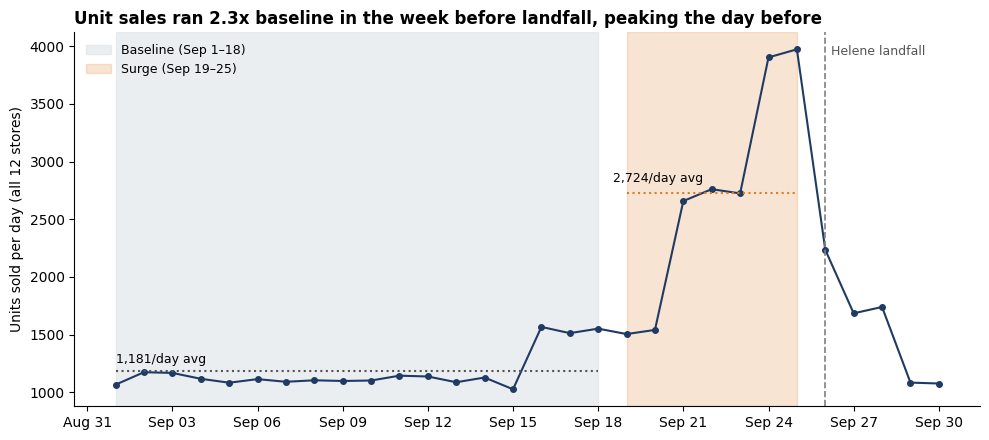

In [148]:
import matplotlib.pyplot as plt, matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily_units.index, daily_units.values, marker='o', ms=4, color='#1f3b63')
ax.axvspan(BASELINE_START, BASELINE_END, color='#d9dee4', alpha=0.5, label='Baseline (Sep 1–18)')
ax.axvspan(SURGE_START, SURGE_END, color='#e07b24', alpha=0.2, label='Surge (Sep 19–25)')
ax.hlines(baseline_avg, BASELINE_START, BASELINE_END, color='#555', ls=':', lw=1.5)
ax.hlines(surge_avg, SURGE_START, SURGE_END, color='#e07b24', ls=':', lw=1.5)
ax.annotate(f'{baseline_avg:,.0f}/day avg', (BASELINE_START, baseline_avg), xytext=(0, 6), textcoords='offset points', fontsize=9)
ax.annotate(f'{surge_avg:,.0f}/day avg', (SURGE_START, surge_avg), xytext=(-10, 8), textcoords='offset points', fontsize=9)
ax.axvline(LANDFALL, color='gray', ls='--', lw=1.2)
ax.annotate('Helene landfall', (LANDFALL, daily_units.max()), xytext=(4, -4), textcoords='offset points', fontsize=9, color='#555')
ax.set_title(f'Unit sales ran {multiple:.1f}x baseline in the week before landfall, peaking the day before',
             loc='left', fontsize=12, fontweight='bold')
ax.set_ylabel('Units sold per day (all 12 stores)')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(frameon=False, fontsize=9, loc='upper left')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

#### Part 4: Top 5 categories
The brief asks for the categories with the greatest surge, their percentage increase, and the daily trend for the top 5.

Surge vs. baseline by category (units/day):
                    baseline_avg  surge_avg  pct_increase
canonical_category                                       
Breakfast                   88.2      378.0         328.5
Emergency                  383.6     1010.6         163.5
Electronics                 74.1      176.4         138.2
Alcohol                     64.7      139.4         115.4
Entertainment              107.6      230.1         113.9
Health                      45.5       95.9         110.7
Household                   90.5      176.7          95.3
Grocery                    179.2      307.9          71.8
Baby                        88.0      134.9          53.2
Snacks                      59.4       73.7          24.1

Peak day for each top-5 category: {'Breakfast': 'Sep 25', 'Emergency': 'Sep 24', 'Electronics': 'Sep 24', 'Alcohol': 'Sep 25', 'Entertainment': 'Sep 25'}


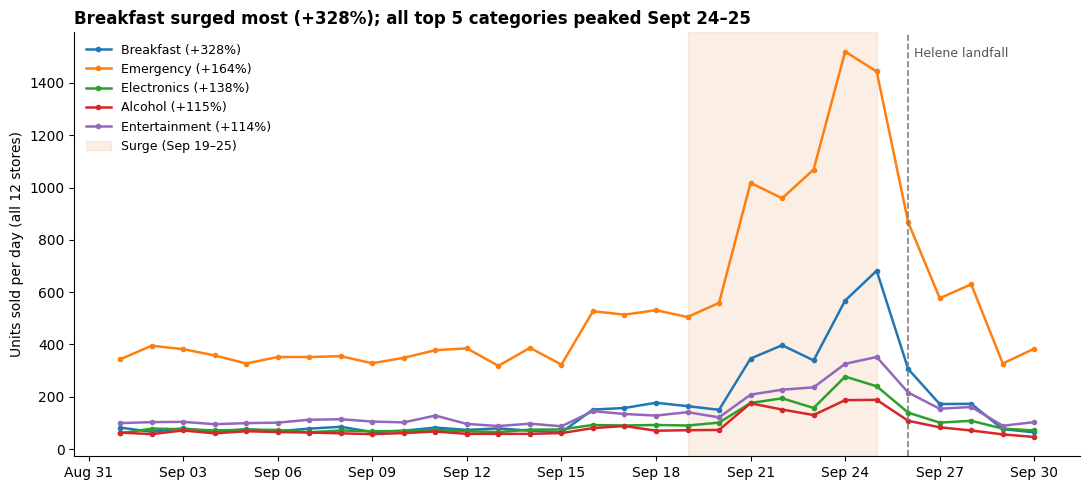

In [149]:
cat_daily = (tx.groupby(['date', 'canonical_category'])['quantity'].sum()
               .unstack(fill_value=0).reindex(all_days, fill_value=0))
cat_summary = pd.DataFrame({
    'baseline_avg': cat_daily[BASELINE_START:BASELINE_END].mean(),
    'surge_avg':    cat_daily[SURGE_START:SURGE_END].mean(),
})
cat_summary['pct_increase'] = (cat_summary['surge_avg'] / cat_summary['baseline_avg'] - 1) * 100
cat_summary = cat_summary.sort_values('pct_increase', ascending=False).round(1)
print('Surge vs. baseline by category (units/day):')
print(cat_summary.to_string())
top5 = cat_summary.head(5).index.tolist()
print('\nPeak day for each top-5 category:', {c: cat_daily[c].idxmax().strftime('%b %d') for c in top5})

fig, ax = plt.subplots(figsize=(11, 5))
for cat in top5:
    ax.plot(cat_daily.index, cat_daily[cat], marker='o', ms=3, lw=1.8,
            label=f"{cat} (+{cat_summary.loc[cat, 'pct_increase']:.0f}%)")
ax.axvspan(SURGE_START, SURGE_END, color='#e07b24', alpha=0.12, label='Surge (Sep 19–25)')
ax.axvline(LANDFALL, color='gray', ls='--', lw=1.2)
ax.annotate('Helene landfall', (LANDFALL, cat_daily[top5].max().max()), xytext=(4, -4),
            textcoords='offset points', fontsize=9, color='#555')
ax.set_title(f"{top5[0]} surged most (+{cat_summary.loc[top5[0], 'pct_increase']:.0f}%); all top 5 categories peaked Sept 24–25",
             loc='left', fontsize=12, fontweight='bold')
ax.set_ylabel('Units sold per day (all 12 stores)')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(frameon=False, fontsize=9, loc='upper left')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

### Q1 Answer

In the 7 days before Helene's landfall (Sept 19–25), our 12 Florida stores sold an average of **2,724 units a day, 2.31x** the **1,181 a day** they sold Sept 1–18. By category, the biggest surges were **Breakfast (+328%)**, **Emergency (+164%)**, **Electronics (+138%)**, **Alcohol (+115%)**, and **Entertainment (+114%)**, and all five peaked on Sept 24–25. The single biggest product mover was Pop-Tarts at **4.3x**. The 127 rows with negative quantities were converted with `abs()`; dropping them or netting them as returns also gives 2.31x, so the finding does not depend on that choice.

### Question 2: The Pop-Tarts Effect (SKU Consolidation)

#### Part 1: Counts and the full mapping

In [150]:
tx = walmart_transactions_cleaned.copy()

raw_count = tx['sku'].nunique()
canonical_count = tx['canonical_sku'].nunique()
print('Distinct SKUs as recorded:', raw_count)
print('Canonical products after consolidation:', canonical_count)
print('SKUs merged away:', raw_count - canonical_count)

mapping_table = (tx.groupby('canonical_sku')
    .agg(raw_codes_merged=('sku', 'nunique'),
         raw_codes=('sku', lambda s: ', '.join(sorted(s.unique()))),
         units=('quantity', 'sum'))
    .sort_values(['raw_codes_merged', 'units'], ascending=False))
display(mapping_table)

Distinct SKUs as recorded: 45
Canonical products after consolidation: 20
SKUs merged away: 25


,raw_codes_merged,raw_codes,units
canonical_sku,,,
POPTART-STRAW,4,"POPTART-STRAW, PT-12, PT_STRAWBERRY, SKU#459812",5025
WTR-24,3,"WATER24PK, WTR-24, WTR_24PK",5044
BAT-AA4,3,"BAT-AA4, BATT-100, BATT_AA_4PK",4186
BG-MONO,3,"BG-MONO, GAME-MONO, MONOPOLY-01",1949
LED-FLASH,2,"FLASH-01, LED-FLASH",2827
CANDLE-EMRG,2,"CANDLE-EMRG, CNDL-EM",2569
SOUP-CAN,2,"CNSOUP-01, SOUP-CAN",2544
BEER-24,2,"BEER-24, LTBEER24",2505
PLAYCARD-STD,2,"CARDS-01, PLAYCARD-STD",2322


#### Part 2: Largest SKU group

In [151]:
largest_family = mapping_table.index[0]
fragmented = (tx[tx['canonical_sku'] == largest_family]
              .groupby('sku')['quantity'].sum().sort_values(ascending=False))
consolidated_total = fragmented.sum()

print(f"Largest SKU group: {largest_family} ({len(fragmented)} raw codes)\n")
for raw_code, units in fragmented.items():
    print(f"  {raw_code:<15} -> {largest_family}   {units:,} units")
print(f"  {'Consolidated total':<15}    {consolidated_total:,} units")
print(f"\nLargest fragment alone: {fragmented.iloc[0]:,} units -> consolidated is {consolidated_total / fragmented.iloc[0]:.1f}x bigger")

raw_rank   = tx.groupby('sku')['quantity'].sum().rank(ascending=False, method='min')
canon_rank = tx.groupby('canonical_sku')['quantity'].sum().rank(ascending=False, method='min')
print(f"Unit-volume rank as best raw code: {int(raw_rank[fragmented.index[0]])} -> consolidated: {int(canon_rank[largest_family])}")

Largest SKU group: POPTART-STRAW (4 raw codes)

  PT-12           -> POPTART-STRAW   1,336 units
  POPTART-STRAW   -> POPTART-STRAW   1,245 units
  PT_STRAWBERRY   -> POPTART-STRAW   1,238 units
  SKU#459812      -> POPTART-STRAW   1,206 units
  Consolidated total    5,025 units

Largest fragment alone: 1,336 units -> consolidated is 3.8x bigger
Unit-volume rank as best raw code: 8 -> consolidated: 2


#### Part 3: Before and after chart

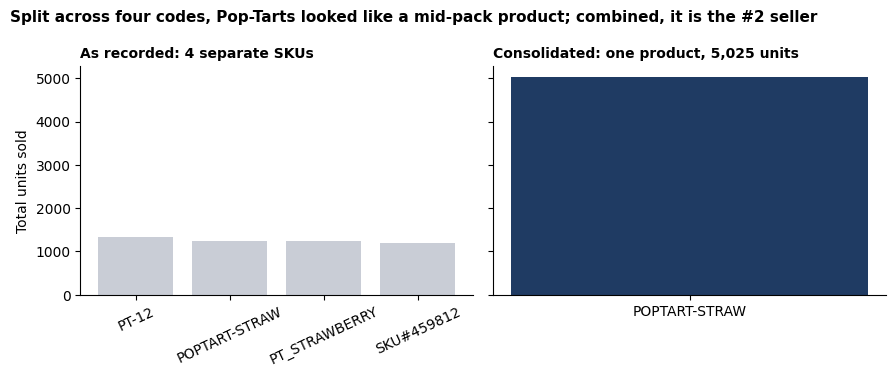

In [152]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} separate SKUs', fontsize=10, loc='left', fontweight='bold')
axes[0].tick_params(axis='x', labelrotation=25)
axes[0].set_ylabel('Total units sold')
axes[1].bar([largest_family], [consolidated_total], color='#1f3b63')
axes[1].set_title(f'Consolidated: one product, {consolidated_total:,} units', fontsize=10, loc='left', fontweight='bold')
for ax in axes:
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
fig.suptitle('Split across four codes, Pop-Tarts looked like a mid-pack product; combined, it is the #2 seller',
             x=0.01, ha='left', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

#### Part 4: Integrity checks

In [153]:
assert tx.groupby('sku')['quantity'].sum().sum() == tx.groupby('canonical_sku')['quantity'].sum().sum(), 'Consolidation changed total units.'
assert consolidated_total == tx.loc[tx['canonical_sku'] == largest_family, 'quantity'].sum()
assert tx.groupby('sku')['canonical_sku'].nunique().max() == 1, 'A raw SKU maps to more than one canonical SKU.'
print(f"Assertions passed: total units = {tx['quantity'].sum():,} before and after consolidation.")

Assertions passed: total units = 48,134 before and after consolidation.


### Q2 Answer

We consolidated **45 distinct SKUs into 20 canonical products** without changing the **48,134-unit total** (asserted in code); the full mapping is in the Part 1 table. The largest group, **Pop-Tarts (`POPTART-STRAW`)**, was spread across **4 codes**: `PT-12`, `POPTART-STRAW`, `PT_STRAWBERRY` and `SKU#459812`.

**True daily volume:** Consolidated, Pop-Tarts sold about **88 units a day** at baseline (Sept 1–18) and **378 a day** in the week before landfall, a **4.3x** surge, peaking at **682 units on Sept 25**.

**Fragmented vs. consolidated:** Split across four codes, each looked like a modest seller of 1,206–1,336 units for the month, and no single code ever topped **240 units in a day**. The best single code (`PT-12`) ranked only **8th** in volume. Combined, Pop-Tarts total **5,025 units, 3.8x its biggest fragment and the #2 product overall**, and the biggest surge of any product.

**Business impact:** In the fragmented view, a planner would see four ordinary breakfast items and likely under-order or replenish each one separately, leading to empty shelves at the peak. In the consolidated view, Pop-Tarts are clearly a top storm item and should be pre-stocked as one product at roughly 4x normal volume before landfall.

### Question 3: Weather Correlation Analysis

#### Necessary Imports

In [154]:
import matplotlib.pyplot as plt
import seaborn as sns

#### Weather and Sales Data Setup

In [155]:
daily_sales = weather_sales_table.groupby(['date', 'canonical_category'], as_index = False).agg(orders = ('transaction_id', 'nunique'), precipitation_sum = ('precipitation_sum', 'first'), windspeed_10m_max = ('windspeed_10m_max', 'first'), pressure_msl_mean = ('pressure_msl_mean', 'first'))
weather_indicators = ['precipitation_sum', 'windspeed_10m_max', 'pressure_msl_mean']
sales_categories = daily_sales['canonical_category'].unique()
lag_range = range(0,5)

correlation_frame = pd.DataFrame(index = sales_categories, columns = weather_indicators, dtype = float)
lag_frame = pd.DataFrame(index = lag_range, columns = sales_categories, dtype = float)

for sales_category in sales_categories:
    category_sales = daily_sales[daily_sales['canonical_category'] == sales_category].sort_values('date')
    for weather_indicator in weather_indicators:
        correlation_frame.loc[sales_category, weather_indicator] = (category_sales['orders'].corr(category_sales[weather_indicator]))
    for lag in lag_range:
        lag_frame.loc[lag, sales_category] = (category_sales['orders'].corr(category_sales['windspeed_10m_max'].shift(-lag)))

#### Weather Indicators and Daily Sales Volume Correlation Table

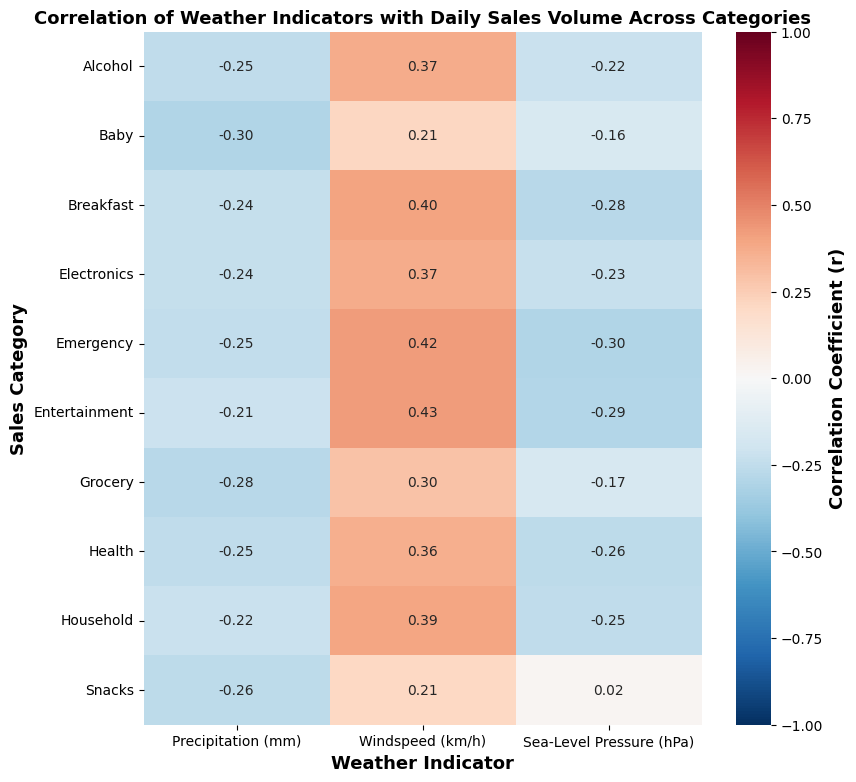

In [156]:
plt.figure(figsize = (9,9))
heatmap = sns.heatmap(correlation_frame, annot = True, fmt = '.2f', cmap = 'RdBu_r', vmin = -1, vmax = 1, xticklabels = ['Precipitation (mm)', 'Windspeed (km/h)', 'Sea-Level Pressure (hPa)'])
heat_bar = heatmap.collections[0].colorbar
heat_bar.set_label('Correlation Coefficient (r)', fontsize = 13, fontweight = 'bold')
plt.title('Correlation of Weather Indicators with Daily Sales Volume Across Categories', fontsize = 13, fontweight = 'bold')
plt.xlabel('Weather Indicator', fontsize = 13, fontweight = 'bold')
plt.ylabel('Sales Category', fontsize = 13, fontweight = 'bold')
plt.show()

The heatmap above reveals that all categories' sales volume share a positive correlation with windspeed (km/h). The windspeed weather indicator has correlation coefficients (r) all within the range 0.21 through 0.43. Among these categories, the entertainment (0.43) and emergency (0.42) categories have the highest correlation coefficients (r). Baby and snacks have the lowest correlation coefficients (r), each equaling 0.21. The precipitation (mm) weather indicator has correlation coefficients (r) all within the range -0.30 through -0.21 while the sea-level pressure (hPa) weather indicator has correlation coefficients (r) all within the range -0.30 through 0.02. Both precipitation and sea-level pressure have overwhelmingly negative correlation coefficients, indicating that there is a negative correlation between these weather indicators and sales volume across almost all categories. Only snacks in sea-level pressure has a positive correlation coefficient (r), equaling 0.02 (still very low). While the windspeed weather indicator did have positive correlation coefficients, they were not high enough to establish an extremely strong positive correlation. It can be concluded that among these weather indicators, windspeed is loosely positively correlated with daily sales volume across all categories while precipitation and sea-level pressure are loosely negatively correlated with daily sales volume across almost all categories. This suggests that windspeed is correlated with higher sales volume across categories while precipitation and sea-level pressure are correlated with lower sales volume across almost all categories, but this correlation alone isn't enough to establish causation. These correlations are computed over 30 days of data (n = 30) using weather from a single Orlando location.

#### Weather Severity Escalation and Purchasing Spikes Lag Table

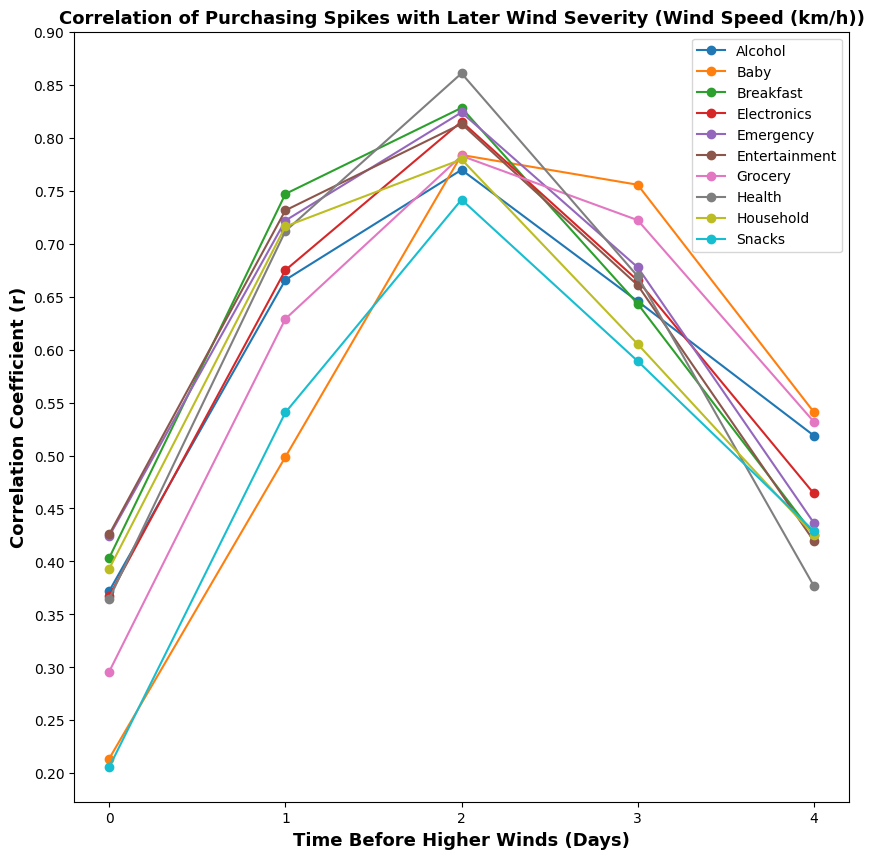

In [157]:
plt.figure(figsize = (10,10))
for sales_category in sales_categories:
    plt.plot(lag_range, lag_frame[sales_category], marker = 'o', label = sales_category)
plt.title('Correlation of Purchasing Spikes with Later Wind Severity (Wind Speed (km/h))', fontsize = 13, fontweight = 'bold')
plt.xlabel('Time Before Higher Winds (Days)', fontsize = 13, fontweight = 'bold')
plt.ylabel('Correlation Coefficient (r)', fontsize = 13, fontweight = 'bold')
plt.xticks(list(lag_range))
plt.yticks(np.arange(0.20, 0.95, 0.05))
plt.legend()
plt.show()

The line chart above reveals that the correlation between purchasing spikes and later weather severity (wind speed) peaks at two days before the anticipated higher winds. This is a consistent result across all categories, with every category experiencing their peak at 2 days before higher winds. This peak is preceded by a steep climb from day 0 and 1 and similarly followed by a steep decline for days 3 and 4. The baby and grocery categories experience the shallowest decline following day 2 while all categories share a similar incline rate prior to day 2. Health has the highest correlation coefficient (r), equaling around 0.86. Snacks has the lowest correlation coefficient (r), equaling around 0.74. Overall, there is a strong correlation between purchasing spikes and higher winds two days later. This indicates that there is a detectable lag of 2 days between weather severity escalation and purchasing spikes. This lag is likely the result of consumers purchasing an increased volume of goods across all categories in response to worsening weather as an anticipatory precaution, but correlation alone can't prove causation. I chose windspeed (km/h) as the weather indicator to detect a lag because it is associated with weather severity escalation, providing a good reflection of changing weather patterns.

### Setup for Questions 4 and 5
Shared settings for Q4 and Q5: Hurricane Helene landfall Sept 26, 2024 (Big Bend, near Perry FL); baseline window Sept 1–18; surge window Sept 19–25 (the 7 days before landfall). Also sets the chart style and helper functions used by both questions.

In [158]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

LANDFALL       = pd.Timestamp('2024-09-26')
BASELINE_START = pd.Timestamp('2024-09-01')
BASELINE_END   = pd.Timestamp('2024-09-18')
SURGE_START    = LANDFALL - pd.Timedelta(days=7)          # Sept 19
SURGE_END      = LANDFALL - pd.Timedelta(days=1)          # Sept 25
LANDFALL_LAT, LANDFALL_LON = 30.10, -83.58                # Helene landfall, near Perry FL

NAVY, ORANGE, GREY, LIGHT = '#1f3b63', '#e07b24', '#9aa3ad', '#d9dee4'
plt.rcParams.update({
    'figure.figsize': (10, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 11, 'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False,
})

def in_window(dates, start, end):
    return (dates >= start) & (dates <= end)

def mark_landfall(ax, label=True):
    ax.axvline(LANDFALL, color=GREY, ls='--', lw=1.2)
    if label:
        ax.annotate('Helene landfall', xy=(LANDFALL, 1), xycoords=('data', 'axes fraction'),
                    xytext=(4, -14), textcoords='offset points', fontsize=9, color='#555')

def format_dates(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

print(f'Baseline: {BASELINE_START:%b %d}–{BASELINE_END:%b %d} | Surge: {SURGE_START:%b %d}–{SURGE_END:%b %d} | Landfall: {LANDFALL:%b %d}')

Baseline: Sep 01–Sep 18 | Surge: Sep 19–Sep 25 | Landfall: Sep 26


## Q4: Store-Level Geographic Patterns

 *Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.*

**Method.**
For each store, we compute three different values based on the clean data of all its transactions.

1. **Surge Multiple**: The value is calculated as the Average Daily Units during the Surge Window divided by the Average Daily Units during the Baseline Window. This represents how large the increase in the number of units was for the store.
2. **Surge Start**: We calculate this by finding the first date after September 10 where the number of daily units at a given store exceeds 150% of what the store’s baseline is. This is the earliest date that the store saw an increase in units due to Hurricane Helene.
3. **Peak Day:** The peak day is defined as the date when there were the most units sold at a store.

Lastly, we join our previous results with stores_cleaned and find out how far each store is away from Helene’s Landfall Point

In [159]:
tx = walmart_transactions_cleaned.copy()
tx['date'] = tx['timestamp'].dt.normalize()

store_daily = tx.groupby(['date', 'store_id'])['quantity'].sum().unstack(fill_value=0)

baseline = store_daily[in_window(store_daily.index, BASELINE_START, BASELINE_END)].mean()
surge    = store_daily[in_window(store_daily.index, SURGE_START, SURGE_END)].mean()
after10  = store_daily[store_daily.index >= pd.Timestamp('2024-09-10')]

store_surge = pd.DataFrame({
    'baseline_units_per_day': baseline.round(1),
    'surge_units_per_day': surge.round(1),
    'surge_multiple': (surge / baseline).round(2),
    'surge_start': after10.gt(1.5 * baseline).idxmax(),
    'peak_day': store_daily.idxmax(),
    'transactions': tx['store_id'].value_counts(),
}).rename_axis('store_id').reset_index()

rows_before = len(store_surge)
store_surge = store_surge.merge(stores_cleaned[['store_id', 'city', 'region', 'latitude', 'longitude']],
                                on='store_id', how='left', validate='one_to_one')
assert len(store_surge) == rows_before and store_surge['city'].notna().all(), 'store join lost or duplicated rows'

store_surge['miles_to_landfall'] = haversine_miles(store_surge['latitude'], store_surge['longitude'],
                                                   LANDFALL_LAT, LANDFALL_LON).round(0).astype(int)
store_surge['days_before_landfall'] = (LANDFALL - store_surge['surge_start']).dt.days
store_surge = store_surge.sort_values('miles_to_landfall').reset_index(drop=True)

print(f'Rows before join: {rows_before} | after join: {len(store_surge)}')
store_surge[['store_id', 'city', 'region', 'miles_to_landfall', 'baseline_units_per_day',
             'surge_units_per_day', 'surge_multiple', 'surge_start', 'days_before_landfall', 'peak_day']]

Rows before join: 12 | after join: 12


,store_id,city,region,miles_to_landfall,baseline_units_per_day,surge_units_per_day,surge_multiple,surge_start,days_before_landfall,peak_day
0,FL619,Tallahassee,Panhandle,48,94.6,225.9,2.39,2024-09-20,6,2024-09-24
1,FL078,Gainesville,North,81,98.3,221.0,2.25,2024-09-21,5,2024-09-25
2,FL412,Jacksonville,North,116,95.9,224.3,2.34,2024-09-21,5,2024-09-25
3,FL105,Tampa,West,163,98.6,232.1,2.35,2024-09-21,5,2024-09-25
4,FL156,Daytona Beach,East,165,99.0,229.7,2.32,2024-09-21,5,2024-09-24
5,FL239,Orlando,Central,171,98.8,210.1,2.13,2024-09-21,5,2024-09-24
6,FL445,St. Petersburg,West,171,101.4,232.6,2.29,2024-09-21,5,2024-09-24
7,FL302,Lakeland,Central,173,102.8,239.6,2.33,2024-09-21,5,2024-09-25
8,FL287,Kissimmee,Central,181,97.8,221.6,2.26,2024-09-21,5,2024-09-25
9,FL710,Pensacola,Panhandle,218,98.9,229.3,2.32,2024-09-21,5,2024-09-25


In [160]:
r = store_surge['miles_to_landfall'].corr(store_surge['surge_multiple'])
z = (store_surge['surge_multiple'] - store_surge['surge_multiple'].mean()) / store_surge['surge_multiple'].std()
store_surge['z_score'] = z.round(2)

print(f'Correlation between distance and surge multiple: r = {r:.2f}  (n = {len(store_surge)} stores)')
print(f"Surge multiple range: {store_surge['surge_multiple'].min()}x – {store_surge['surge_multiple'].max()}x")
print()
print('Stores sorted by how unusual their surge was (z-score):')
store_surge.assign(abs_z=z.abs()).sort_values(['abs_z'], ascending=False)[
    ['store_id', 'city', 'miles_to_landfall', 'surge_multiple', 'z_score', 'surge_start']].head(4)

Correlation between distance and surge multiple: r = 0.19  (n = 12 stores)
Surge multiple range: 2.13x – 2.43x

Stores sorted by how unusual their surge was (z-score):


,store_id,city,miles_to_landfall,surge_multiple,z_score,surge_start
5,FL239,Orlando,171,2.13,-2.31,2024-09-21
11,FL330,Miami,364,2.43,1.61,2024-09-18
0,FL619,Tallahassee,48,2.39,1.09,2024-09-20
1,FL078,Gainesville,81,2.25,-0.74,2024-09-21


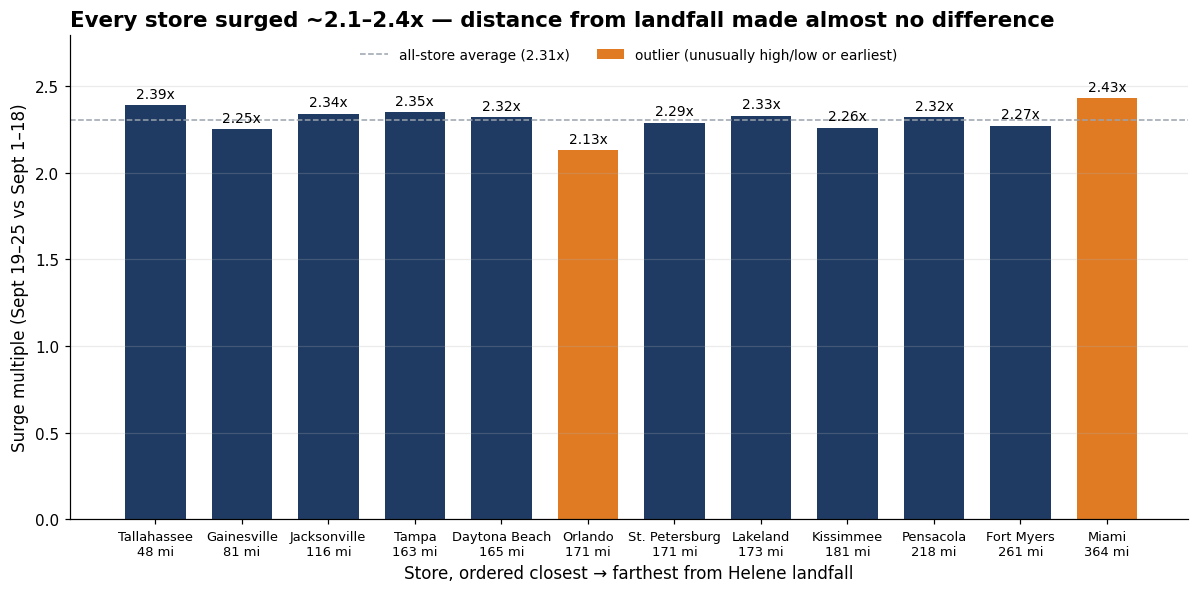

In [161]:
# CHART Q4a, surge multiple by store, ordered closest -> farthest from landfall
outlier_ids = store_surge.loc[store_surge['z_score'].abs() >= 1.5, 'store_id'].tolist()
earliest_id = store_surge.loc[store_surge['surge_start'].idxmin(), 'store_id']
highlight = set(outlier_ids) | {earliest_id}

fig, ax = plt.subplots(figsize=(11, 5.5))
labels = [f"{c}\n{m} mi" for c, m in zip(store_surge['city'], store_surge['miles_to_landfall'])]
colors = [ORANGE if s in highlight else NAVY for s in store_surge['store_id']]
bars = ax.bar(labels, store_surge['surge_multiple'], color=colors, width=0.7)
ax.bar_label(bars, labels=[f'{v:.2f}x' for v in store_surge['surge_multiple']], padding=3, fontsize=9)
ax.axhline(store_surge['surge_multiple'].mean(), color=GREY, ls='--', lw=1,
           label=f"all-store average ({store_surge['surge_multiple'].mean():.2f}x)")
ax.bar(0, 0, color=ORANGE, label='outlier (unusually high/low or earliest)')
ax.legend(loc='upper center', ncol=2, fontsize=9)

ax.set_ylim(0, store_surge['surge_multiple'].max() * 1.15)
ax.set_title('Every store surged ~2.1–2.4x — distance from landfall made almost no difference')
ax.set_ylabel('Surge multiple (Sept 19–25 vs Sept 1–18)')
ax.set_xlabel('Store, ordered closest → farthest from Helene landfall')
ax.tick_params(axis='x', labelsize=8.5)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

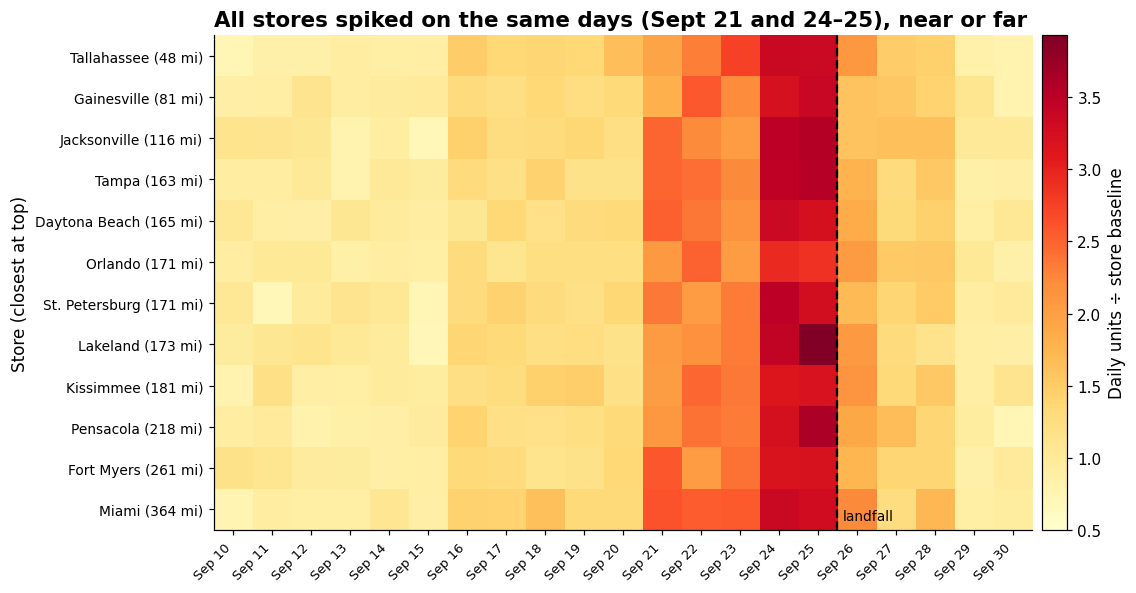

In [162]:
# CHART Q4b:timing: each store's daily units as a multiple of its own baseline
indexed = (store_daily / baseline)[store_surge['store_id']]
indexed = indexed[indexed.index >= pd.Timestamp('2024-09-10')]

fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(indexed.T.values, aspect='auto', cmap='YlOrRd', vmin=0.5, vmax=indexed.values.max())
ax.set_yticks(range(len(store_surge)))
ax.set_yticklabels([f"{c} ({m} mi)" for c, m in zip(store_surge['city'], store_surge['miles_to_landfall'])], fontsize=9)
ax.set_xticks(range(len(indexed.index)))
ax.set_xticklabels([d.strftime('%b %d') for d in indexed.index], rotation=45, ha='right', fontsize=8.5)
lf = list(indexed.index).index(LANDFALL)
ax.axvline(lf - 0.5, color='black', lw=1.5, ls='--')
ax.text(lf - 0.35, len(store_surge) - 0.75, 'landfall', fontsize=9, color='black')
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label('Daily units ÷ store baseline')
ax.set_title('All stores spiked on the same days (Sept 21 and 24–25), near or far')
ax.set_ylabel('Store (closest at top)')
plt.tight_layout()
plt.show()

### Q4 Answer

In reality there is almost no difference in the rate of increase in sales at each store. All twelve stores increased their normal daily sales by a range of **2.13 to 2.43 times**. The proximity of the landfall did not indicate how large an increase would be. In fact the relationship was weak, **r = 0.19 (n = 12)**, and actually had a slight bias toward larger increases as the stores got farther from the center. In addition, timing was nearly identical. At nearly all of the stores sales increased to over one and one half times the normal baseline on **September 21** and reached peak levels on either **September 24 or 25** regardless of location. The stores are located at distances ranging from 48 miles (Tallahassee) to 364 miles (Miami) from the center.

**The outliers were:**
- **Miami (FL330):** It was the store that was the furthest from the center (364 mi) but it experienced the largest increase in sales (**2.43x**) and started its run-up in sales three days before most other stores began theirs (**Sept 18**). Our belief is that consumers in South Florida respond to the forecast cone, which covers much of Florida, rather than to the eventual landfall track.
- **Orlando (FL239):** This store had the smallest increase in sales (**2.13x**) and was more than two standard deviations below the mean (**z = −2.31**) despite being closer to the center of the storm (171 miles) than some of the other stores.
- **Tallahassee (FL619):** Although it was the closest store (48 miles) to the center and started increasing its sales a day before most other stores (**Sept 20**), it did not have an increase in sales that exceeded those of all of the other stores.

**Limitations:** Twelve stores may be too few to provide accurate data. Distance was measured from each store to where Helene actually landed. However, customers begin preparing for the potential impact of a storm many days before the actual landfall based on forecast paths. Due to missing information, Tallahassee's coordinates were filled in during data cleaning.

## Q5: Signal vs. Artifact: The Board Games Investigation

*The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?*

**Plan for four tests:**
1. **Test one:** Replicate the +250% in the `daily_sales_summary` table of SQLite.
2. **Test two:** Category lumping test. What is included under "Entertainment" within the transaction data?
3. **Test three:** SKU miscoding test. Is the board game product split across SKUs, and are there any miscoded rows?
4. **Test four:** Inventory test. Does inventory for the board game in the `inventory_levels` table move with the actual sell-through (as it should), or does it fall behind?

### Test 1: Reproduce the +250% from the SQLite database

In [163]:
query = '''
SELECT date, category, SUM(total_units) AS units
FROM daily_sales_summary
GROUP BY date, category
'''
db_cat = pd.read_sql_query(query, conn)
db_cat['date'] = pd.to_datetime(db_cat['date'], format='mixed')
db_cat = db_cat.groupby(['date', 'category'])['units'].sum().unstack()

db_base  = db_cat[in_window(db_cat.index, BASELINE_START, BASELINE_END)].mean()
db_surge = db_cat[in_window(db_cat.index, SURGE_START, SURGE_END)].mean()
db_peak  = db_cat.loc[[pd.Timestamp('2024-09-24'), pd.Timestamp('2024-09-25')]].mean()

db_compare = pd.DataFrame({
    '7-day surge vs baseline (%)': ((db_surge / db_base - 1) * 100).round(0),
    'peak days Sept 24–25 vs baseline (%)': ((db_peak / db_base - 1) * 100).round(0),
}).sort_values('peak days Sept 24–25 vs baseline (%)', ascending=False)
db_compare

,7-day surge vs baseline (%),peak days Sept 24–25 vs baseline (%)
category,,
Breakfast,207.0,406.0
Emergency,156.0,270.0
Entertainment,130.0,244.0
Health,107.0,189.0
Household,94.0,180.0
Alcohol,106.0,178.0
Electronics,90.0,165.0
Baby,52.0,108.0
Grocery,58.0,84.0


In the database, Entertainment is up **+244%** if you only compare the two peak days (Sept 24–25) to the baseline. Over the full 7-day surge window it's only **+130%**. So the "+250%" headline depends on which days you pick.

### Test 2 — Category lumping: what is inside "Entertainment"?

In [164]:
ent = tx[tx['canonical_category'] == 'Entertainment']

print('Products inside the Entertainment category (cleaned SKUs):')
print(ent.groupby('canonical_sku')['quantity'].sum().rename('units').to_string())
print()
print('Raw category labels used for those rows (before cleaning):')
pd.crosstab(ent['canonical_sku'], ent['category'])

Products inside the Entertainment category (cleaned SKUs):
canonical_sku
BG-MONO         1949
PLAYCARD-STD    2322

Raw category labels used for those rows (before cleaning):


category,ENTERTAINMENT,Entertainment,Games & Entertainment,entertainment
canonical_sku,,,,
BG-MONO,317,313,345,313
PLAYCARD-STD,270,310,274,304


In [165]:
ent_daily = ent.groupby(['date', 'canonical_sku'])['quantity'].sum().unstack(fill_value=0)
ent_daily['ENTERTAINMENT (total)'] = ent_daily.sum(axis=1)

def surge_pct(daily):
    b = daily[in_window(daily.index, BASELINE_START, BASELINE_END)].mean()
    s = daily[in_window(daily.index, SURGE_START, SURGE_END)].mean()
    return ((s / b - 1) * 100).round(0)

lumping = pd.DataFrame({'7-day surge vs baseline (%)': surge_pct(ent_daily)})
lumping = lumping.rename(index={'BG-MONO': 'Board games (Monopoly)', 'PLAYCARD-STD': 'Playing cards'})
lumping

,7-day surge vs baseline (%)
canonical_sku,
Board games (Monopoly),150.0
Playing cards,87.0
ENTERTAINMENT (total),114.0


"Entertainment" is actually two products: Monopoly and playing cards. All four raw category labels (Entertainment, ENTERTAINMENT, entertainment, Games & Entertainment) contain both. Separated out, board games are up **+150%** and playing cards **+87%**. Combined, the category is +114%.

### Test 3: SKU miscoding / fragmentation

In [166]:
mono = tx[tx['canonical_sku'] == 'BG-MONO']
print('Monopoly appears under', mono['sku'].nunique(), 'different raw SKUs and', mono['product_name'].str.strip().nunique(), 'product names:')
print(mono.groupby('sku')['quantity'].sum().rename('units').to_string())
print()

mono_store = mono.groupby(['date', 'store_id'])['quantity'].sum().unstack(fill_value=0)
by_store = (mono_store[in_window(mono_store.index, SURGE_START, SURGE_END)].mean()
            / mono_store[in_window(mono_store.index, BASELINE_START, BASELINE_END)].mean()).round(2)
print(f'Board-game surge multiple by store: min {by_store.min()}x, median {by_store.median()}x, max {by_store.max()}x')
print('Stores with a surge > 1.5x:', (by_store > 1.5).sum(), 'of', len(by_store))

print()
print('Entertainment rows that are NOT Monopoly or cards:', (~ent['canonical_sku'].isin(['BG-MONO', 'PLAYCARD-STD'])).sum())
print('Monopoly rows filed outside Entertainment:', (mono['canonical_category'] != 'Entertainment').sum())

Monopoly appears under 3 different raw SKUs and 3 product names:
sku
BG-MONO        637
GAME-MONO      676
MONOPOLY-01    636

Board-game surge multiple by store: min 1.93x, median 2.295x, max 3.33x
Stores with a surge > 1.5x: 12 of 12

Entertainment rows that are NOT Monopoly or cards: 0
Monopoly rows filed outside Entertainment: 0


Monopoly is split across **3 SKUs** (BG-MONO, GAME-MONO, MONOPOLY-01), so any one SKU only shows about a third of the sales. But the surge shows up at **all 12 stores**, and there are **0** miscoded rows in either direction. This isn't one store or one bad code creating the spike.

### Test 4: Inventory: real sell-through, or reporting lag?

In [167]:
inv_q = '''
SELECT date, sku, AVG(units_on_hand) AS on_hand
FROM inventory_levels
GROUP BY date, sku
'''
inv_daily = pd.read_sql_query(inv_q, conn)
inv_daily['date'] = pd.to_datetime(inv_daily['date'], format='mixed')
inv_daily['canonical_sku'] = inv_daily['sku'].map(sku_mapping).fillna(inv_daily['sku'])
inv_daily = inv_daily.groupby(['date', 'canonical_sku'])['on_hand'].mean().unstack()   # average units on hand per store

compare_skus = {'BG-MONO': 'Board games (Monopoly)', 'WTR-24': 'Bottled water', 'POPTART-STRAW': 'Strawberry Pop-Tarts'}
inv_compare = inv_daily[list(compare_skus)].rename(columns=compare_skus)

unmapped = sorted(set(inventory_clean['canonical_sku']) - set(tx['canonical_sku']))
print('Inventory SKUs with no match in the transactions:', unmapped)
print(inventory_clean[inventory_clean['canonical_sku'].isin(unmapped)].groupby('canonical_sku').size().rename('rows').to_string())
inv_compare.loc['2024-09-18':'2024-09-26']

Inventory SKUs with no match in the transactions: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']
canonical_sku
LEGACY-PT      90
MISC-001       84
OLD-BATT-50    90
UNKNOWN-99     91


canonical_sku,Board games (Monopoly),Bottled water,Strawberry Pop-Tarts
date,,,
2024-09-18,129.944444,130.933333,125.250000
2024-09-19,157.555556,139.333333,92.500000
2024-09-20,133.666667,92.138889,134.125000
2024-09-21,28.888889,26.688889,32.500000
2024-09-22,34.111111,39.861111,41.622222
2024-09-23,36.683333,37.500000,36.500000
2024-09-24,47.555556,30.916667,40.111111
2024-09-25,28.166667,34.444444,42.250000
2024-09-26,40.222222,61.277778,44.333333


Board-game stock was built up Sept 12–20, then dropped sharply on **Sept 21**, the same day sales jumped. Water and Pop-Tarts show the same pattern. There's no delay between sales and inventory, so this isn't a reporting-lag artifact. One gap: 4 inventory codes (UNKNOWN-99, MISC-001, LEGACY-PT, OLD-BATT-50) don't match any product, so some board-game stock could be hiding under them.

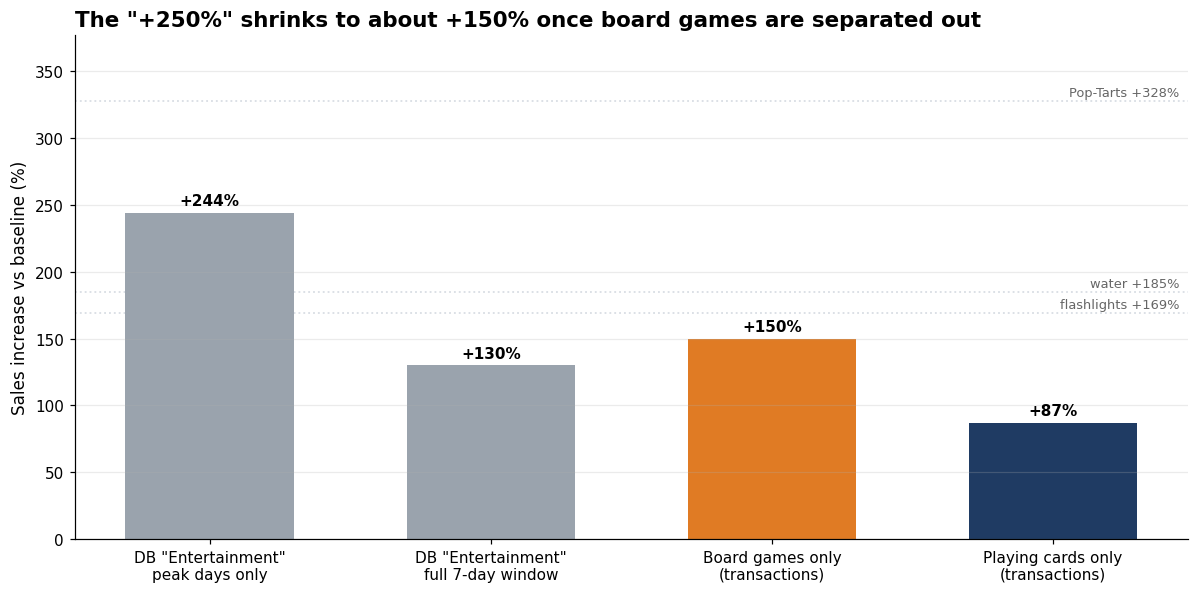

In [168]:
# CHART Q5a:
evidence = pd.Series({
    'DB "Entertainment"\npeak days only': db_compare.loc['Entertainment', 'peak days Sept 24–25 vs baseline (%)'],
    'DB "Entertainment"\nfull 7-day window': db_compare.loc['Entertainment', '7-day surge vs baseline (%)'],
    'Board games only\n(transactions)': lumping.loc['Board games (Monopoly)'].iloc[0],
    'Playing cards only\n(transactions)': lumping.loc['Playing cards'].iloc[0],
})
benchmarks = surge_pct(tx.groupby(['date', 'canonical_sku'])['quantity'].sum().unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = [GREY, GREY, ORANGE, NAVY]
bars = ax.bar(evidence.index, evidence.values, color=colors, width=0.6)
ax.bar_label(bars, labels=[f'+{v:.0f}%' for v in evidence.values], padding=3, fontsize=10, fontweight='bold')
for sku, name in [('WTR-24', 'water'), ('LED-FLASH', 'flashlights'), ('POPTART-STRAW', 'Pop-Tarts')]:
    ax.axhline(benchmarks[sku], color=LIGHT, lw=1.2, ls=':', zorder=0)
    ax.text(3.45, benchmarks[sku] + 4, f'{name} +{benchmarks[sku]:.0f}%', ha='right', fontsize=8.5, color='#666')
ax.set_title('The "+250%" shrinks to about +150% once board games are separated out')
ax.set_ylabel('Sales increase vs baseline (%)')
ax.set_ylim(0, max(evidence.max(), benchmarks['POPTART-STRAW']) * 1.15)
ax.grid(axis='x', visible=False)
ax.title.set_fontsize(12.5)
plt.tight_layout()
plt.show()

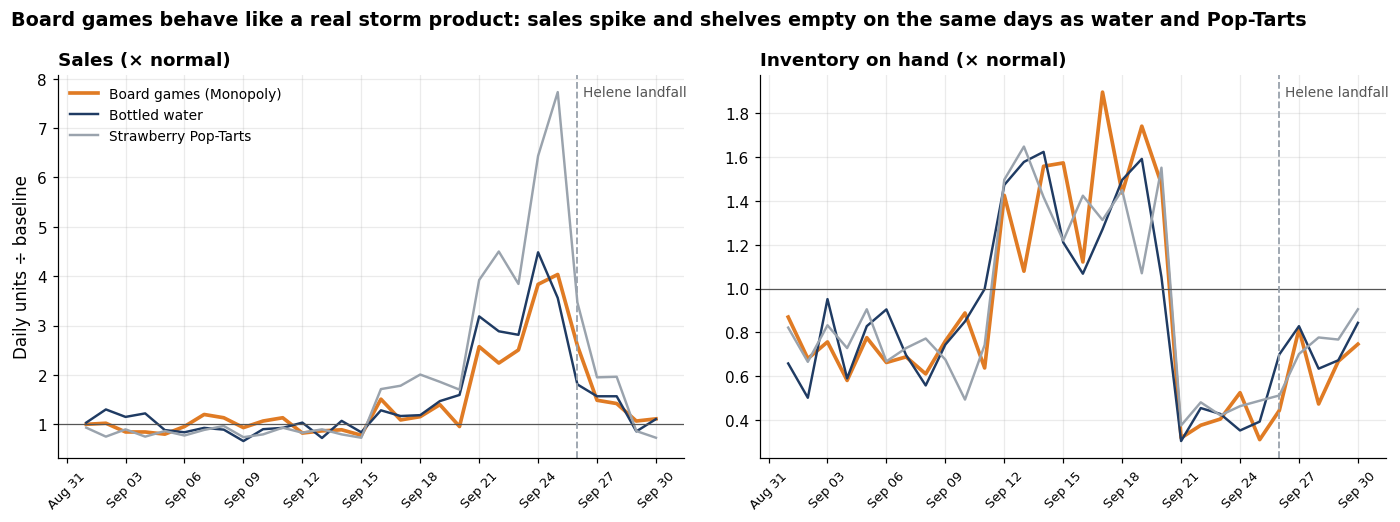

In [169]:
# CHART Q5b:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)

units = tx.groupby(['date', 'canonical_sku'])['quantity'].sum().unstack(fill_value=0)[list(compare_skus)].rename(columns=compare_skus)
units_idx = units / units[in_window(units.index, BASELINE_START, BASELINE_END)].mean()
for col, c in zip(units_idx.columns, [ORANGE, NAVY, GREY]):
    axes[0].plot(units_idx.index, units_idx[col], color=c, lw=2.4 if c == ORANGE else 1.6, label=col)
axes[0].axhline(1, color='#555', lw=0.8)
axes[0].set_title('Sales (× normal)', fontsize=12)
axes[0].set_ylabel('Daily units ÷ baseline')

inv_idx = inv_compare / inv_compare[in_window(inv_compare.index, BASELINE_START, BASELINE_END)].mean()
for col, c in zip(inv_idx.columns, [ORANGE, NAVY, GREY]):
    axes[1].plot(inv_idx.index, inv_idx[col], color=c, lw=2.4 if c == ORANGE else 1.6, label=col)
axes[1].axhline(1, color='#555', lw=0.8)
axes[1].set_title('Inventory on hand (× normal)', fontsize=12)

for ax in axes:
    mark_landfall(ax)
    format_dates(ax)
    ax.tick_params(axis='x', rotation=45, labelsize=8.5)
axes[0].legend(loc='upper left', fontsize=9)
fig.suptitle('Board games behave like a real storm product: sales spike and shelves empty on the same days as water and Pop-Tarts',
             x=0.01, ha='left', fontsize=12.5, fontweight='bold')
plt.tight_layout()
plt.show()

### Q5 Answer and Recommendation

**Verdict:** The +250% was an overstatement of what actually occurred. The true board-game lift is about **+150% (2.5x normal)**.

**We know this demand was real because:**
1. Monopoly sales rose about 2.5x, similar to the increases in battery sales (**2.49x**) and flashlight sales (**2.69x**);
2. the increase happened in **all 12 stores**; and
3. board-game inventory levels began dropping on **Sept. 21**, the same day sales jumped, just like water and Pop-Tarts. This means there was **no** reporting delay.

**The +250% was inflated in three ways:**
1. The window chosen made it appear as though sales increased by **+244%** (peak days only), when over the full week they really only increased by **+130%**;
2. playing card sales were included within the "Entertainment" category, and those items increased by only **+87%**; and
3. Monopoly has **three SKUs**, and **four** inventory codes could not be matched to any product.

**Recommendation:** I would say yes, that Walmart should have an excess of board games in each Florida store location, however this excess should be approximately **2.5 times normal sales volume** rather than 3.5 times as suggested in the prompt. The excess of board games should be placed at all locations throughout Florida (**as Q4 demonstrated demand increases across the entire state**) 5-7 days prior to the projected landfall. Since board games do not "go bad" or expire, if we overstock it would simply mean marking down our inventory of board games after the storm, which is a less costly approach than having to throw away product. Prior to the next storm, I believe Walmart should fix the SKU mapping and separate the board game and playing card categories from one another, allowing the dashboard to report the true amount of board games.

**Limitations/Assumptions:** This is based upon information related to a single storm and synthetic data. Since the database table scales significantly larger than the transaction file, we were forced to compare percent changes, because comparing raw units was not possible.

# Reflection Questions

### Question 1: Data Quality Impact

The main problem related to the quality of data involved fragmentation of SKUs. Specifically for the Strawberry Pop-Tarts product, there were four SKUs (PT-12, POPTART-STRAW, PT_STRAWBERRY, and SKU#459812). Each of these SKUs identified the same product; however, each provided slightly different product name descriptions as well as varying categorizations. When analyzed individually, the number of sales for each SKU ranged from 1,206 to 1,336 per month. The highest number of daily sales for any of the individual SKUs was 240. The single best performing SKU (PT-12) in terms of monthly unit sales ranked eighth in overall unit sales. To resolve the SKU fragmentation issue we created a "mapping" table that directed all raw SKU information to a singular canonical SKU. We also included validation rules to verify that consolidation of the SKU information did not affect the overall unit sales total (48,134 units). Upon consolidation, Pop-Tarts accounted for 5,025 units (ranked second overall), reached a one-day peak of 682 units on September 25, and represented the greatest increase of any product at 4.3 times its base level in the week before landfall. Had we not resolved this issue, it appears that Pop-Tarts would have appeared as four average breakfast products rather than the singular greatest storm-related product. As such, all downstream results would have been impacted including: the top products in Question 1, the answer to Question 2, and the recommendations for stocking levels.

### Question 2: ETL Trade-offs

The decision to perform a left-join of sales data with weather data was based primarily on preserving the supplied sales data. It's a much easier task to fill in missing weather data for a given date than it would be to recover sales data that was dropped. An alternative way that we considered to accomplish this join was performing an INNER JOIN. By doing so, we may have impacted our results because the entire row of the sales data would've been removed when no corresponding weather data existed, which would've caused us to lose both sales and weather data. However, the LEFT JOIN method preserved the sales data for each row regardless of whether or not matching weather data could be found. Therefore, the safer and most effective approach was clearly a LEFT JOIN; ultimately resulting in the joining of weather data to all 24,648 rows of sales data. Although, in hindsight, an INNER JOIN would've been equally safe with regards to losing data due to failed joins, since every sales date had matching weather data – we made the correct choice.

### Question 3: Pipeline Trust

We concur with the CDO. While many of our analyses used common statistical techniques — such as calculating averages, ratios and correlation — nearly all of our problems were caused by how data was transmitted or converted between each stage of the process rather than by the specific calculations. The weakest link in the chain was the transition between the data-cleaning portion of our project and the actual questions we analyzed. There was a time when the cleaning stage removed the original `sku`, `product_name`, and `category` fields from `walmart_transactions_cleaned`. This removal did not produce an error message in the cleaning step itself, but broke code that followed later in the pipeline. It made Q5 unable to identify which raw SKUs and categories were combined under the label "Entertainment" and made Q2 unable to present the before-and-after view of the four Pop-Tart SKUs. Additionally, we wrote some portions of the analysis separately in individual scratch-notebooks that read local files named differently, so code that ran on someone's own copy did not always run properly when run from the shared notebook. As an example, at one time we produced a chart showing sales of Pop-Tarts with 3,780 units sold versus 5,025 total units sold due to filtering out the canonical SKU (POPTART-STRAW) itself. Some of these errors did not produce a crash at all — only plausible-looking incorrect numbers — which is why the pipeline creates a larger risk than the analysis. Our internal safeguards included assertions about the number of rows and total quantity of items being processed. For instance, we knew the weather-join should have returned all 24,648 rows; and we knew that consolidation should have preserved all 48,134 units. Another safeguard involved running the entire notebook from a blank kernel.

### Question 4: Business vs. Data

To determine whether there was an actual increase in demand in the wake of Hurricane Helene, we first needed to verify that the reported 250 percent increase in board game sales was true. The data supported both sides of this argument. There were many indicators that suggested increased demand existed: the number of Monopoly units sold during the week leading up to landfall increased by approximately 2.5 times; the spike in Monopoly unit sales occurred at all twelve stores; and board game inventory decreased on September 21st (the exact date Monopoly unit sales spiked); as did the water and Pop-Tarts. However, the reported 250 percent figure was inflated because it is based solely on comparison of sales from the two highest days of the surge compared to the baseline. More specifically, the 250 percent figure is for the entire "entertainment" category, which lumps Monopoly together with playing card sales. Separated out, board games increased by approximately 150 percent, while playing card sales only increased by approximately 87 percent. When we evaluated the potential risks associated with making either error, we determined that stocking board games has relatively low risk. While overstocking board games will result in a markdown after the storm passes, understocking could leave a large portion of our customer base unable to purchase board games at the moment they desire to do so. Therefore, due to the limited risk associated with overstocking board games relative to the significant potential loss associated with missing sales opportunities, we were willing to recommend additional board game stock; however, we are limiting our recommendation to only what we believe is reasonable based on the available data and evidence (2.5 times normal volume). Additionally, since Q4 demonstrated that the surge occurred at each store statewide, we recommended that all stores receive the additional stock. With additional time or information regarding future storms or seasonal trends, we would further analyze whether board games tend to experience surges prior to all hurricane events or if this event was unique to Hurricane Helene. This analysis will help us better understand how to approach recommendations regarding board game inventory increases during similar events in the future. As such, we also plan to research how best to match the four unmatched inventory codes (UNKNOWN-99, MISC-001, LEGACY-PT, OLD-BATT-50) to their respective products and then create separate product categories for board games and playing cards to allow for accurate tracking and reporting. Finally, if board games continue to trend upward with respect to sales throughout multiple events, we can increase our initial order size. Conversely, if no consistent trend emerges, we may choose to decrease the size of our initial order, ultimately recommending only enough stock for a small-scale test.

### Question 5 – team collaboration
**How we split the work:** as per our charter, we decided to divide the work based on the stages of the pipeline. Nate was responsible for data cleaning and decision log; Jack was responsible for weather API, the weather/sales join as well as Q3; Maya was responsible for q1 & q2 and she built the slide deck; alex was responsible for Q4 & Q5, recommendation, readme, and pulling all sections together into the final notebook. first each member worked individually in their own scratch notebooks and when they were completed they pulled their work over to the shared notebook.

**If we had another week what would be done differently:** with an additional week we could have created the shared team notebook in the first week of work rather than at the end of our time. This way if there were issues with integration such as mismatched file paths or dropped columns, these issues would be identified sooner rather than later. Also, we would have agreed upon table/column names earlier on and we would have pulled weather information for each store's location vs just Orlando. Both Q3 and Q4 would benefit from this.

**Most valuable skill each member contributed to the project:**
- **Nate:** he provided thorough data cleaning across all five files which each section of the report depended upon.
- **Jack:** he provided a reliable API pipeline using retries, fallbacks, and validated joins.
- **Maya:** she provided clear visual storytelling in her charts for q1 & q2 and in her slide deck.
- **Alex:** he provided multiple angles on the board game Question and was able to integrate all members' work into one notebook that runs from top to bottom.